In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats as sps
import os, warnings, time

# --- Group configuration ---
group_csv   = "group_gh_ssids.csv"
group_label = "Group G+H"
group_short = "group_gh"

# --- Paths ---
elpac_clean_dir = "../1095 Data/ELPAC/Cleaned"
enrollment_dir  = "../1095 Data/Enrollment"
os.makedirs("plots", exist_ok=True)

# --- Analysis parameters ---
MIN_CELL       = 25    # minimum students per category level
MIN_DISTRICT   = 15    # minimum students per district
MIN_COUNTRY    = 100   # minimum students to keep a birth country separate

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

print(f"Configured for {group_label}")

# --- CALPADS RaceEthnicity code labels (verified against StudentRace1Code) ---
race_labels = {
    "A": "Asian",
    "B": "Black",
    "D": "NotReported",
    "F": "Filipino",
    "H": "Hispanic_Latino",
    "I": "AmerIndian_AKNative",
    "P": "PacificIslander",
    "T": "TwoOrMore",
    "W": "White",
}
# --- Birth country code → name (ISO 3166-1 alpha-2, plus CALPADS extras) ---
country_labels = {
    # Above the 100-student threshold in this cohort
    "AF": "Afghanistan",   "AM": "Armenia",     "CN": "China",
    "CO": "Colombia",      "GT": "Guatemala",   "HN": "Honduras",
    "HT": "Haiti",         "MX": "Mexico",      "NI": "Nicaragua",
    "RU": "Russia",        "SV": "El Salvador", "UA": "Ukraine",
    "VN": "Vietnam",
    # Non-country levels created by the collapsing step
    "UU": "Unknown",       "Other": "Other (pooled)",  "Missing": "Missing",
    # Below threshold here, but retained in case MIN_COUNTRY is lowered
    "BR": "Brazil",        "PE": "Peru",        "EC": "Ecuador",
    "PH": "Philippines",   "KR": "South Korea", "JP": "Japan",
    "IN": "India",         "PK": "Pakistan",    "BD": "Bangladesh",
    "IQ": "Iraq",          "SY": "Syria",       "YE": "Yemen",
    "EG": "Egypt",         "ET": "Ethiopia",    "SO": "Somalia",
    "KZ": "Kazakhstan",    "UZ": "Uzbekistan",  "MD": "Moldova",
    "BY": "Belarus",       "TH": "Thailand",    "KH": "Cambodia",
    "MM": "Myanmar",       "TR": "Turkey",      "IR": "Iran",
    "JO": "Jordan",        "LB": "Lebanon",     "VE": "Venezuela",
    "AR": "Argentina",     "CL": "Chile",       "DO": "Dominican Rep.",
    "CU": "Cuba",          "TW": "Taiwan",      "HK": "Hong Kong",
    "FJ": "Fiji",          "NP": "Nepal",       "UM": "U.S. Outlying",
    "US": "United States",
}
print(f"Loaded {len(country_labels)} birth country labels")
# --- Outcome switch: flip to Z after seeing Cell 3's verdict ---
#OUTCOME  = "ZGain_fixed"      # or "ZGain_fixed"  (orig: "ScoreGain")
OUTCOME  = "ScoreGain"      # or "ZGain_fixed"  (orig: "ScoreGain")
BASELINE = "S1_wg"         # or "Z1_fixed" (orig: "Summ1Score_c")

print(f"Outcome: {OUTCOME}, baseline covariate: {BASELINE}")

Configured for Group G+H
Loaded 53 birth country labels
Outcome: ScoreGain, baseline covariate: S1_wg


In [3]:
# --- Group SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"{group_label}: {len(group_ssids):,} students")

# --- Summative 1 (2022) and Summative 3 (2024) — SAME SCALE ---
def load_summative(filename):
    d = pd.read_csv(os.path.join(elpac_clean_dir, filename), low_memory=False)
    d = d.apply(lambda c: c.str.strip() if c.dtype == "object" else c)
    d["OverallScaleScore"] = pd.to_numeric(d["OverallScaleScore"], errors="coerce")
    d["TestStartDate"]     = pd.to_datetime(d["TestStartDate"], errors="coerce")
    return d

summ1 = load_summative("SummativeElpac_22_clean.csv")
summ3 = load_summative("SummativeElpac_24_clean.csv")
print(f"Summative 2022: {len(summ1):,} rows")
print(f"Summative 2024: {len(summ3):,} rows")

# --- Enrollment (2021-22, the baseline year) ---
enrollment = pd.read_csv(os.path.join(enrollment_dir, "CEnrollment_21-22.csv"), low_memory=False)
enrollment_group = (
    enrollment[enrollment["SSID"].isin(group_ssids)]
    .drop_duplicates(subset="SSID", keep="first")
)
print(f"Enrollment records: {len(enrollment_group):,}")

# --- Verify the scales now match ---
print("\nScale check (these should be comparable):")
print(f"  Summative 2022: min={summ1['OverallScaleScore'].min():.0f}, "
      f"max={summ1['OverallScaleScore'].max():.0f}, mean={summ1['OverallScaleScore'].mean():.0f}")
print(f"  Summative 2024: min={summ3['OverallScaleScore'].min():.0f}, "
      f"max={summ3['OverallScaleScore'].max():.0f}, mean={summ3['OverallScaleScore'].mean():.0f}")

Group G+H: 12,918 students
Summative 2022: 302,476 rows
Summative 2024: 291,920 rows
Enrollment records: 12,918

Scale check (these should be comparable):
  Summative 2022: min=201, max=1950, mean=1476
  Summative 2024: min=201, max=1868, mean=1464


In [4]:
# --- Outcome: Summative 3 − Summative 1 (same scale, valid difference) ---
s1 = (summ1[summ1["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]]
      .dropna().rename(columns={"OverallScaleScore": "Summ1Score"}))
s3 = (summ3[summ3["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]]
      .dropna().rename(columns={"OverallScaleScore": "Summ3Score"}))

df = s1.merge(s3, on="SSID", how="inner")
df["ScoreGain"] = df["Summ3Score"] - df["Summ1Score"]

# Center the baseline — controls for regression to the mean
df["Summ1Score_c"] = df["Summ1Score"] - df["Summ1Score"].mean()

print(f"Students with both summative scores: {len(df):,}")
print(f"\nOutcome (Summative 2024 − Summative 2022):")
print(df["ScoreGain"].describe())

# --- Sanity check: this should now be a plausible magnitude ---
mean_gain = df["ScoreGain"].mean()
if abs(mean_gain) > 300:
    print(f"\n*** WARNING: mean gain of {mean_gain:.0f} still looks implausible ***")
else:
    print(f"\nMean gain of {mean_gain:.1f} points over two years — plausible.")

Students with both summative scores: 12,918

Outcome (Summative 2024 − Summative 2022):
count    12918.000000
mean       103.504180
std         73.097826
min       -235.000000
25%         55.000000
50%         92.000000
75%        137.000000
max        472.000000
Name: ScoreGain, dtype: float64

Mean gain of 103.5 points over two years — plausible.


In [5]:
# --- Does grade-specific scaling distort the raw-point outcome? ---
# Fixed-reference standardization: BOTH years scaled by the 2022 grade-specific SD.
# Unlike per-year standardization, this preserves between-grade differences.

zdf = df[["SSID", "Summ1Score", "Summ3Score", "ScoreGain"]].copy()
zdf = zdf.merge(
    enrollment_group[["SSID", "GradeLevelCode"]].assign(
        GradeLevelCode=lambda d: d["GradeLevelCode"].astype(str).str.strip()
    ),
    on="SSID", how="left"
)

# --- How much does the scale actually stretch across grades? ---
grade_stats = zdf.groupby("GradeLevelCode")["Summ1Score"].agg(["size", "mean", "std"])
grade_stats.columns = ["N", "Mean_2022", "SD_2022"]
grade_stats = grade_stats.sort_values("SD_2022", ascending=False)

print("2022 SUMMATIVE DISTRIBUTION BY GRADE")
print("=" * 56)
print(grade_stats.to_string())

# Grades with too few students for a stable SD
UNSTABLE_N = 30
unstable = grade_stats[grade_stats["N"] < UNSTABLE_N].index.tolist()
if unstable:
    print(f"\nGrades with N < {UNSTABLE_N} (SD unreliable, excluded from the check): {unstable}")

stable = grade_stats[grade_stats["N"] >= UNSTABLE_N]
sd_ratio = stable["SD_2022"].max() / stable["SD_2022"].min()
print(f"\nSD range across stable grades: {stable['SD_2022'].min():.1f} to "
      f"{stable['SD_2022'].max():.1f}  (ratio {sd_ratio:.2f}x)")

# --- Fixed-reference z-scores: same mu/sd applied to both years ---
g  = zdf.groupby("GradeLevelCode")["Summ1Score"]
mu = g.transform("mean")
sd = g.transform("std")

zdf["Z1_fixed"]    = (zdf["Summ1Score"] - mu) / sd
zdf["Z3_fixed"]    = (zdf["Summ3Score"] - mu) / sd      # SAME mu/sd, not re-derived
zdf["ZGain_fixed"] = zdf["Z3_fixed"] - zdf["Z1_fixed"]

corr = zdf["ZGain_fixed"].corr(zdf["ScoreGain"])

print("\n" + "=" * 56)
print("SCALING CHECK")
print("=" * 56)
print(zdf["ZGain_fixed"].describe().to_string())
print(f"\nCorrelation, fixed-reference z-gain vs raw-point gain: {corr:.4f}")

# --- Per-grade comparison (these should NOT all be zero) ---
by_grade = zdf.groupby("GradeLevelCode").agg(
    N=("ScoreGain", "size"),
    RawGain=("ScoreGain", "mean"),
    ZGain_fixed=("ZGain_fixed", "mean"),
    SD_2022=("Summ1Score", "std"),
).sort_values("RawGain", ascending=False)
by_grade["RawRank"] = by_grade["RawGain"].rank(ascending=False).astype(int)
by_grade["ZRank"]   = by_grade["ZGain_fixed"].rank(ascending=False).astype(int)
by_grade["RankShift"] = by_grade["RawRank"] - by_grade["ZRank"]

print("\nMean gain by grade — raw points vs SD units:")
print(by_grade.to_string())

max_shift = by_grade.loc[by_grade["N"] >= UNSTABLE_N, "RankShift"].abs().max()

print("\n" + "-" * 56)
if corr > 0.95 and max_shift <= 2:
    print("VERDICT: grade scaling is NOT distorting the results.")
    print("Keep ScoreGain — raw points are easier to interpret.")
    USE_Z_OUTCOME = False
else:
    print("*** VERDICT: grade scaling matters. ***")
    print(f"    correlation = {corr:.4f}, max grade rank shift = {max_shift}")
    print("    Refit on ZGain_fixed and compare grade coefficients.")
    USE_Z_OUTCOME = True
print("-" * 56)

# --- Carry the z-outcome forward so the model can use it ---
df = df.merge(zdf[["SSID", "ZGain_fixed", "Z1_fixed"]], on="SSID", how="left")
print(f"\nAdded ZGain_fixed and Z1_fixed to df. Columns: {df.shape[1]}")

2022 SUMMATIVE DISTRIBUTION BY GRADE
                   N    Mean_2022    SD_2022
GradeLevelCode                              
02               914  1330.794311  86.510820
01              1258  1329.647059  85.914396
KN              3583  1353.538376  78.247917
03               868  1374.675115  66.149183
10               541  1418.878004  62.944831
05               708  1385.283898  60.877180
04               832  1381.504808  57.202198
06               722  1402.470914  55.004424
08               695  1414.772662  54.440011
07               752  1408.666223  51.406596
09              1957  1405.065406  49.456606
11                85  1409.917647  48.229662
PS                 3  1372.333333  17.785762

Grades with N < 30 (SD unreliable, excluded from the check): ['PS']

SD range across stable grades: 48.2 to 86.5  (ratio 1.79x)

SCALING CHECK
count    12918.000000
mean         1.552628
std          1.091803
min         -3.578895
25%          0.843473
50%          1.374943
75%         

In [6]:
demo_cols = [
    "SSID", "GradeLevelCode", "SocioeconomicallyDisadvantaged",
    "TitleIPartCMigrant", "HomelessProgram", "Foster",
    "PrimaryLanguageCode", "StudentGenderCode",
    "ParentGuardianHighestEducationLevelCode",
    "RaceEthnicity", "StudentBirthCountryCode", "Districtname",
]
# UnaccompaniedYouthIndicator excluded — 88.9% missing

df = df.merge(enrollment_group[demo_cols], on="SSID", how="left")
print(f"After demographic merge: {len(df):,} students, {df.shape[1]} columns")

# --- Normalize: 'nan'/'none'/'' strings become real NaN ---
raw_cats = [c for c in demo_cols if c not in ("SSID",)]
for col in raw_cats:
    df[col] = df[col].astype(str).str.strip()
    df.loc[df[col].str.lower().isin(["nan", "none", ""]), col] = np.nan

print("\nMissingness after normalization:")
for col in raw_cats:
    n_miss = df[col].isna().sum()
    print(f"  {col:<42} {n_miss:>7,} missing ({n_miss/len(df)*100:>5.1f}%)")

After demographic merge: 12,918 students, 18 columns

Missingness after normalization:
  GradeLevelCode                                   0 missing (  0.0%)
  SocioeconomicallyDisadvantaged                   0 missing (  0.0%)
  TitleIPartCMigrant                               0 missing (  0.0%)
  HomelessProgram                                  0 missing (  0.0%)
  Foster                                           0 missing (  0.0%)
  PrimaryLanguageCode                            216 missing (  1.7%)
  StudentGenderCode                                0 missing (  0.0%)
  ParentGuardianHighestEducationLevelCode         57 missing (  0.4%)
  RaceEthnicity                                    0 missing (  0.0%)
  StudentBirthCountryCode                          0 missing (  0.0%)
  Districtname                                     0 missing (  0.0%)


In [7]:
def collapse_threshold(s, min_n=MIN_CELL, other="Other", missing="Missing",
                       drop_residual=True, verbose=True):
    """
    NOMINAL variables. Levels below min_n pool into 'Other'.

    Unlike the previous version, this RE-CHECKS the pooled bucket: if 'Other'
    still falls below min_n, those rows are set to NaN (drop_residual=True) so
    they can be excluded, rather than becoming an unstable one-off category.
    """
    s = s.copy()
    counts = s.value_counts(dropna=True)
    small = set(counts[counts < min_n].index)

    out = s.apply(lambda x: missing if pd.isna(x) else (other if x in small else x))

    # Re-check every resulting level, including 'Other' and 'Missing'
    post = out.value_counts()
    still_small = [lvl for lvl, n in post.items() if n < min_n]

    if still_small:
        if verbose:
            for lvl in still_small:
                print(f"    post-pool level '{lvl}' has {post[lvl]} < {min_n} "
                      f"→ {'set to NaN' if drop_residual else 'kept'}")
        if drop_residual:
            out = out.where(~out.isin(still_small), np.nan)

    return out


def collapse_ordinal(s, merge_map, missing="Missing"):
    """
    ORDINAL variables (parent education).
    Adjacent levels merged via an explicit map, preserving order.
    Never dump ordinal levels into a generic 'Other' — that destroys the ordering.
    """
    s = s.copy()
    out = s.apply(lambda x: missing if pd.isna(x) else merge_map.get(str(x), str(x)))
    return out


def collapse_domain(s, group_map, other="Other", missing="Missing"):
    """
    Variables with natural structure (grade level → school stage).
    Mapping is supplied explicitly by domain knowledge.
    """
    s = s.copy()
    out = s.apply(lambda x: missing if pd.isna(x) else group_map.get(str(x), other))
    return out


def report_collapse(before, after, name):
    print(f"\n{name}")
    print(f"  before: {before.nunique(dropna=True):>3} levels, {before.isna().sum():>6,} missing")
    print(f"  after:  {after.nunique():>3} levels")
    vc = after.value_counts()
    for val, n in vc.items():
        flag = "  <-- below MIN_CELL" if n < MIN_CELL else ""
        print(f"    {str(val):<28} {n:>7,}{flag}")

In [8]:
work = df.copy()

# --- Birth country grouping (before other work) ---
# (keep whatever you already have here for BirthCountryGroup if it differs)

# --- Nominal, threshold-collapsed ---
print("Grade:")
work["Grade"]        = collapse_threshold(work["GradeLevelCode"],          min_n=MIN_CELL)
work["S1_wg"] = work["Summ1Score"] - work.groupby("Grade")["Summ1Score"].transform("mean")
print("Race:")
work["Race"] = work["RaceEthnicity"].map(race_labels).fillna(work["RaceEthnicity"])
work["Race"] = collapse_threshold(work["Race"], min_n=MIN_CELL)
print("BirthCountry:")
work["BirthCountry"] = collapse_threshold(work["StudentBirthCountryCode"], min_n=MIN_COUNTRY)

# --- Ordinal ---
parent_ed_map = {
    "10.0": "1_NotHSGrad",   "10": "1_NotHSGrad",
    "11.0": "2_HSGrad",      "11": "2_HSGrad",
    "12.0": "3_SomeCollege", "12": "3_SomeCollege",
    "13.0": "4_CollegePlus", "13": "4_CollegePlus",
    "14.0": "4_CollegePlus", "14": "4_CollegePlus",
    "15.0": "5_Declined",    "15": "5_Declined",
}
work["ParentEd"] = collapse_ordinal(work["ParentGuardianHighestEducationLevelCode"], parent_ed_map)

# --- Language ---
lang = work["PrimaryLanguageCode"]
work["Language"] = np.select([lang.isna(), lang == "01"],
                             ["Unknown", "Spanish"], default="Non-Spanish")

# --- Binaries: these previously bypassed collapsing entirely ---
for col, new in [
    ("StudentGenderCode",              "Gender"),
    ("SocioeconomicallyDisadvantaged", "SED"),
    ("TitleIPartCMigrant",             "Migrant"),
    ("HomelessProgram",                "Homeless"),
    ("Foster",                         "Foster"),
]:
    print(f"{new}:")
    work[new] = collapse_threshold(work[col], min_n=MIN_CELL)

# --- Report ---
for src, new in [
    ("GradeLevelCode", "Grade"),
    ("ParentGuardianHighestEducationLevelCode", "ParentEd"),
    ("RaceEthnicity", "Race"),
    ("StudentBirthCountryCode", "BirthCountry"),
    ("PrimaryLanguageCode", "Language"),
    ("StudentGenderCode", "Gender"),
    ("SocioeconomicallyDisadvantaged", "SED"),
    ("TitleIPartCMigrant", "Migrant"),
    ("HomelessProgram", "Homeless"),
    ("Foster", "Foster"),
]:
    report_collapse(df[src], work[new], new)

Grade:
    post-pool level 'Other' has 3 < 25 → set to NaN
Race:
    post-pool level 'Other' has 14 < 25 → set to NaN
BirthCountry:
Gender:
    post-pool level 'Other' has 1 < 25 → set to NaN
SED:
Migrant:
Homeless:
Foster:
    post-pool level 'Other' has 16 < 25 → set to NaN

Grade
  before:  13 levels,      0 missing
  after:   12 levels
    KN                             3,583
    09                             1,957
    01                             1,258
    02                               914
    03                               868
    04                               832
    07                               752
    06                               722
    05                               708
    08                               695
    10                               541
    11                                85

ParentEd
  before:   6 levels,     57 missing
  after:    6 levels
    4_CollegePlus                  5,468
    5_Declined                     4,733
    2_HSGrad    

In [9]:
model_cats = ["Grade", "ParentEd", "Race", "BirthCountry", "Language",
              "Gender", "SED", "Migrant", "Homeless"] # Foster removed

# --- Districts: drop small ones ---
work["District"] = work["Districtname"].fillna("Missing")
dsize = work["District"].value_counts()
small_d = dsize[dsize < MIN_DISTRICT].index.tolist()
if small_d:
    print(f"Dropping {len(small_d)} districts with <{MIN_DISTRICT} students "
          f"({dsize[small_d].sum():,} students)")
    work = work[~work["District"].isin(small_d)]

# --- Drop students left in unusable categories by the post-pool check ---
n_before = len(work)
work = work.dropna(subset=model_cats)
n_dropped = n_before - len(work)
print(f"Dropped {n_dropped} students in below-minimum categories "
      f"({n_dropped/n_before*100:.2f}%)")

# --- Outcome must be present ---
model_df = work.dropna(subset=[OUTCOME, BASELINE]).reset_index(drop=True)

print(f"\n{'='*64}")
print(f"FINAL MODELING DATASET — {group_label}")
print(f"{'='*64}")
print(f"Students:   {len(model_df):>8,}  ({len(model_df)/len(df)*100:.1f}% of {len(df):,} retained)")
print(f"Districts:  {model_df['District'].nunique():>8,}")
print(f"Outcome:    {OUTCOME}")
print(f"Mean:       {model_df[OUTCOME].mean():>8.3f} (SD {model_df[OUTCOME].std():.3f})")
print(f"{'='*64}")

# --- Hard check: nothing below MIN_CELL reaches the model ---
print("\nFinal cell-size check:")
violations = []
for col in model_cats:
    vc = model_df[col].value_counts()
    bad = vc[vc < MIN_CELL]
    if len(bad):
        violations.append((col, bad.to_dict()))
        print(f"  *** {col}: {bad.to_dict()}")
    else:
        print(f"  {col:<16} {vc.nunique():>2} levels, smallest = {vc.min():,}")

assert not violations, f"Cells below MIN_CELL={MIN_CELL}: {violations}"
print("\nAll cells meet minimum size.")

Dropped 18 students in below-minimum categories (0.14%)

FINAL MODELING DATASET — Group G+H
Students:     12,900  (99.9% of 12,918 retained)
Districts:        23
Outcome:    ScoreGain
Mean:        103.486 (SD 73.103)

Final cell-size check:
  Grade            12 levels, smallest = 85
  ParentEd          6 levels, smallest = 57
  Race              8 levels, smallest = 47
  BirthCountry     15 levels, smallest = 99
  Language          3 levels, smallest = 214
  Gender            2 levels, smallest = 6,012
  SED               2 levels, smallest = 3,025
  Migrant           2 levels, smallest = 165
  Homeless          2 levels, smallest = 1,426

All cells meet minimum size.


In [10]:
fixed_cat = model_cats   # District is the random effect

RACE_REF = "Hispanic_Latino"
race_levels = set(model_df["Race"].unique())
if RACE_REF not in race_levels:
    raise ValueError(
        f"Reference level '{RACE_REF}' not found in Race.\n"
        f"Found: {sorted(race_levels)}"
    )

# --- Build the term list once; reused by the LRT cell ---
def build_formula(outcome, baseline, terms):
    rhs = [baseline] + [
        f'C({v}, Treatment(reference="{RACE_REF}"))' if v == "Race" else f"C({v})"
        for v in terms
    ]
    return f"{outcome} ~ " + " + ".join(rhs)

full_formula = build_formula(OUTCOME, BASELINE, fixed_cat)
print(full_formula, "\n")

t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    full_model = smf.mixedlm(
        full_formula, data=model_df, groups="District"
    ).fit(reml=True, method="lbfgs", maxiter=2000)
print(f"Fitted in {time.time()-t0:.1f}s — converged: {full_model.converged}\n")

print(full_model.summary())

vb = float(full_model.cov_re.iloc[0, 0])
vw = float(full_model.scale)
icc = vb / (vb + vw)

unit = "points" if OUTCOME == "ScoreGain" else "SD units"

print(f"\n{'='*64}")
print(f"VARIANCE DECOMPOSITION  (outcome: {OUTCOME})")
print(f"{'='*64}")
print(f"Between-district variance: {vb:>10.4f}  (SD {np.sqrt(vb):.4f} {unit})")
print(f"Within-district variance:  {vw:>10.4f}  (SD {np.sqrt(vw):.4f} {unit})")
print(f"ICC = {icc:.4f} → {icc*100:.2f}% of variation is between districts")
print(f"{'='*64}")

ScoreGain ~ S1_wg + C(Grade) + C(ParentEd) + C(Race, Treatment(reference="Hispanic_Latino")) + C(BirthCountry) + C(Language) + C(Gender) + C(SED) + C(Migrant) + C(Homeless) 

Fitted in 0.3s — converged: True

                                      Mixed Linear Model Regression Results
Model:                                MixedLM                   Dependent Variable:                   ScoreGain  
No. Observations:                     12900                     Method:                               REML       
No. Groups:                           23                        Scale:                                3227.1398  
Min. group size:                      27                        Log-Likelihood:                       -70336.5788
Max. group size:                      5397                      Converged:                            Yes        
Mean group size:                      560.9                                                                      
-------------------------------

In [11]:
# --- Fit both outcomes; compare grade coefficients ---
comp_models = {}
for outc, base in [("ScoreGain", "Summ1Score_c"), ("ZGain_fixed", "Z1_fixed")]:
    if outc not in model_df.columns or base not in model_df.columns:
        print(f"SKIP {outc}: column missing — did Cell 3 run?")
        continue
    f = build_formula(outc, base, fixed_cat)
    sub = model_df.dropna(subset=[outc, base])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm(f, data=sub, groups="District").fit(
            reml=True, method="lbfgs", maxiter=2000)
    comp_models[outc] = m
    print(f"{outc:<14} n={len(sub):,}  converged={m.converged}")

if len(comp_models) == 2:
    raw_g = comp_models["ScoreGain"].fe_params.filter(like="C(Grade)")
    z_g   = comp_models["ZGain_fixed"].fe_params.filter(like="C(Grade)")

    grade_comp = pd.DataFrame({
        "Grade":     raw_g.index.str.extract(r"\[T\.(.+?)\]")[0].values,
        "Raw_pts":   raw_g.values,
        "Z_SDunits": z_g.reindex(raw_g.index).values,
    })
    grade_comp["Raw_rank"] = grade_comp["Raw_pts"].rank(ascending=False).astype(int)
    grade_comp["Z_rank"]   = grade_comp["Z_SDunits"].rank(ascending=False).astype(int)
    grade_comp["Shift"]    = grade_comp["Raw_rank"] - grade_comp["Z_rank"]

    print("\n" + "="*70)
    print("GRADE COEFFICIENTS — raw points vs SD units")
    print("="*70)
    print(grade_comp.sort_values("Raw_pts", ascending=False).to_string(index=False))

    max_shift = int(grade_comp["Shift"].abs().max())
    rank_corr = grade_comp["Raw_pts"].corr(grade_comp["Z_SDunits"], method="spearman")
    print("-"*70)
    print(f"Max rank shift: {max_shift}   |   Spearman correlation: {rank_corr:.3f}")

    if max_shift <= 2 and rank_corr > 0.90:
        print("\nVERDICT: grade ordering is STABLE across scalings.")
        print("Report the raw-point results — they are easier to interpret.")
    else:
        print("\n*** VERDICT: grade ordering CHANGES with scaling. ***")
        print("The raw-point grade ranking is a scaling artifact.")
        print("Set OUTCOME='ZGain_fixed', BASELINE='Z1_fixed' in Cell 0 and re-run.")
    print("="*70)

ScoreGain      n=12,900  converged=True
ZGain_fixed    n=12,900  converged=True

GRADE COEFFICIENTS — raw points vs SD units
Grade    Raw_pts  Z_SDunits  Raw_rank  Z_rank  Shift
   02   8.890862   0.080976         1       6     -5
   03   1.174576   0.099726         2       5     -3
   05   0.826636   0.137237         3       4     -1
   04  -0.391267   0.269785         4       1      3
   10  -2.234866  -0.272033         5      11     -6
   11  -3.823645   0.140327         6       3      3
   09  -3.912296   0.183190         7       2      5
   06  -4.202657   0.050744         8       7      1
   08 -12.355133  -0.215023         9      10     -1
   KN -12.849434  -0.176959        10       9      1
   07 -15.288466  -0.119820        11       8      3
----------------------------------------------------------------------
Max rank shift: 6   |   Spearman correlation: 0.427

*** VERDICT: grade ordering CHANGES with scaling. ***
The raw-point grade ranking is a scaling artifact.
Set OUTCOM

In [12]:
params = full_model.fe_params
pvals  = full_model.pvalues[params.index]

def var_effects(varname):
    mask = params.index.str.startswith(f"C({varname}")   # note: no closing paren
    if not mask.any():
        return None
    coefs  = params[mask]
    levels = coefs.index.str.extract(r"\[T\.(.+?)\]")[0].tolist()
    e = pd.DataFrame({
        "Level":  levels + ["(reference)"],
        "Effect": coefs.values.tolist() + [0.0],
        "P":      pvals[mask].values.tolist() + [np.nan],
    })
    counts = model_df[varname].value_counts()
    ref_level = set(counts.index) - set(levels)
    e["N"] = e["Level"].map(counts)
    if ref_level:
        e.loc[e["Level"] == "(reference)", "N"] = counts[list(ref_level)[0]]
        e.loc[e["Level"] == "(reference)", "Level"] = f"{list(ref_level)[0]} (ref)"
    return e

rows = []
for v in fixed_cat:
    e = var_effects(v)
    if e is None:
        continue

    # Restrict to levels meeting the minimum before picking the "largest"
    e_valid = e[(e["N"] >= MIN_CELL) | e["N"].isna()]
    if len(e_valid) == 0:
        e_valid = e

    idx = e_valid["Effect"].abs().idxmax()

    rows.append({
        "Variable":      v,
        "Type":          "Fixed",
        "N_Levels":      len(e),
        # Range also computed on valid levels only
        "EffectRange":   e_valid["Effect"].max() - e_valid["Effect"].min(),
        "LargestLevel":  e_valid.loc[idx, "Level"],
        "LargestEffect": e_valid.loc[idx, "Effect"],
        "LargestN":      e_valid.loc[idx, "N"],
        "LargestP":      e_valid.loc[idx, "P"],
        "N_Significant": int((e["P"] < 0.05).sum()),
    })

# if "Summ1Score_c" in params.index:
#     spread = model_df["Summ1Score_c"].max() - model_df["Summ1Score_c"].min()
#     rows.append({
#         "Variable": "Summ1Score_c", "Type": "Fixed (continuous)", "N_Levels": np.nan,
#         "EffectRange": abs(params["Summ1Score_c"] * spread),
#         "LargestLevel": "per 1 point", "LargestEffect": params["Summ1Score_c"],
#         "LargestN": len(model_df),
#         "N_Significant": int(pvals["Summ1Score_c"] < 0.05),
#     })
if BASELINE in params.index:
    spread = model_df[BASELINE].max() - model_df[BASELINE].min()
    rows.append({
        "Variable": BASELINE, "Type": "Fixed (continuous)", "N_Levels": np.nan,
        "EffectRange": abs(params[BASELINE] * spread),
        "LargestLevel": "per 1 unit", "LargestEffect": params[BASELINE],
        "LargestN": len(model_df),
        "LargestP": pvals[BASELINE],
        "N_Significant": int(pvals[BASELINE] < 0.05),
    })


re_vals = np.array([np.asarray(v).ravel()[0] for v in full_model.random_effects.values()])
top_d = max(full_model.random_effects,
            key=lambda k: abs(np.asarray(full_model.random_effects[k]).ravel()[0]))
rows.append({
    "Variable": "District", "Type": "Random", "N_Levels": len(re_vals),
    "EffectRange": re_vals.max() - re_vals.min(),
    "LargestLevel": top_d, "LargestEffect": re_vals[np.argmax(np.abs(re_vals))],
    "LargestN": model_df["District"].value_counts()[top_d],
    "N_Significant": np.nan,
})

effects_df = pd.DataFrame(rows)
print(effects_df.sort_values("EffectRange", ascending=False).to_string(index=False))

    Variable               Type  N_Levels  EffectRange         LargestLevel  LargestEffect  LargestN      LargestP  N_Significant
       S1_wg Fixed (continuous)       NaN   313.115140           per 1 unit      -0.578408   12900.0  0.000000e+00            1.0
       Grade              Fixed      12.0    69.819828                   08     -61.592555     695.0 4.074783e-115           11.0
BirthCountry              Fixed      15.0    44.656778                   GT     -27.636112    2538.0  2.173807e-13           12.0
    District             Random      23.0    29.144252 Grossmont Union High     -15.899212      75.0           NaN            NaN
        Race              Fixed       8.0    27.927083            TwoOrMore      14.046309      91.0  3.878086e-02            2.0
    ParentEd              Fixed       6.0    17.682655              Missing     -17.682655      57.0  4.248892e-02            3.0
    Language              Fixed       3.0     6.825429              Spanish       6.825429

In [13]:
print("Fitting ML baseline...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    full_ml = smf.mixedlm(full_formula, data=model_df, groups="District").fit(
        reml=False, method="lbfgs", maxiter=2000)
ll_full, k_full = full_ml.llf, len(full_ml.fe_params)
print(f"Log-likelihood: {ll_full:.2f}\n")

all_terms = [BASELINE] + fixed_cat
lrt_rows = []

for v in all_terms:
    if v == BASELINE:
        red_formula = f"{OUTCOME} ~ " + " + ".join(
            f'C({t}, Treatment(reference="{RACE_REF}"))' if t == "Race" else f"C({t})"
            for t in fixed_cat)
    else:
        red_formula = build_formula(OUTCOME, BASELINE, [t for t in fixed_cat if t != v])

    print(f"  dropping {v:<16}", end=" ", flush=True)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            red = smf.mixedlm(red_formula, data=model_df, groups="District").fit(
                reml=False, method="lbfgs", maxiter=2000)
        lr = 2 * (ll_full - red.llf)
        dfd = k_full - len(red.fe_params)
        p = sps.chi2.sf(lr, dfd) if dfd > 0 else np.nan
        lrt_rows.append({"Variable": v, "LR_ChiSq": lr, "df": dfd, "LRT_P": p})
        print(f"chi2={lr:>8.1f}  p={p:.2e}")
    except Exception as ex:
        print(f"FAILED: {ex}")
        lrt_rows.append({"Variable": v, "LR_ChiSq": np.nan, "df": np.nan, "LRT_P": np.nan})

# District variance component (boundary test — halve the p-value)
print(f"  dropping {'District':<16}", end=" ", flush=True)
ols_equiv = smf.ols(full_formula, data=model_df).fit()
lr_d = 2 * (ll_full - ols_equiv.llf)
p_d_halved   = 0.5 * sps.chi2.sf(lr_d, 1)
p_d_unhalved = sps.chi2.sf(lr_d, 1)
lrt_rows.append({"Variable": "District", "LR_ChiSq": lr_d, "df": 1, "LRT_P": p_d_halved})
print(f"chi2={lr_d:>8.1f}  p={p_d_halved:.2e}")

lrt_df = pd.DataFrame(lrt_rows)

# --- Boundary test documentation ---
print("\n" + "-" * 64)
print("BOUNDARY TEST NOTE (district variance component)")
print("-" * 64)
print("Testing a variance component against zero puts the null on the")
print("boundary of the parameter space. P-value halved per Self & Liang (1987).")
print(f"  halved (reported):  p = {p_d_halved:.2e}")
print(f"  unhalved (conservative): p = {p_d_unhalved:.2e}")
print("Conclusion is unchanged either way." if p_d_unhalved < 0.05
      else "*** Conclusion DIFFERS between the two — report both. ***")
print("-" * 64)

# --- Multiple comparison corrections ---
from statsmodels.stats.multitest import multipletests

lrt_valid = lrt_df.dropna(subset=["LRT_P"]).copy()
rej_bonf, p_bonf, _, _ = multipletests(lrt_valid["LRT_P"], alpha=0.05, method="bonferroni")
rej_bh,   p_bh,   _, _ = multipletests(lrt_valid["LRT_P"], alpha=0.05, method="fdr_bh")

lrt_valid["P_Bonferroni"] = p_bonf
lrt_valid["P_BH_FDR"]     = p_bh
lrt_valid["Sig_Raw"]      = lrt_valid["LRT_P"] < 0.05
lrt_valid["Sig_Bonf"]     = rej_bonf
lrt_valid["Sig_BH"]       = rej_bh

lrt_df = lrt_df.merge(
    lrt_valid[["Variable", "P_Bonferroni", "P_BH_FDR", "Sig_Raw", "Sig_Bonf", "Sig_BH"]],
    on="Variable", how="left"
)

print("\n" + "=" * 88)
print(f"MULTIPLE COMPARISON CORRECTION ({len(lrt_valid)} tests)")
print("=" * 88)
print(lrt_df[["Variable", "LR_ChiSq", "LRT_P", "P_Bonferroni", "P_BH_FDR",
              "Sig_Raw", "Sig_Bonf", "Sig_BH"]].to_string(index=False))
print("-" * 88)
print(f"Significant — raw: {lrt_df['Sig_Raw'].sum()}, "
      f"Bonferroni: {lrt_df['Sig_Bonf'].sum()}, BH-FDR: {lrt_df['Sig_BH'].sum()}")

lost = lrt_df[lrt_df["Sig_Raw"] & ~lrt_df["Sig_Bonf"].fillna(False)]["Variable"].tolist()
if lost:
    print(f"\nSignificant at p<0.05 but NOT after Bonferroni: {lost}")
    print("  → treat these as suggestive, not established.")
print("=" * 88)

Fitting ML baseline...
Log-likelihood: -70418.20

  dropping S1_wg            chi2=  4721.2  p=0.00e+00
  dropping Grade            chi2=  1417.7  p=1.82e-297
  dropping ParentEd         chi2=   120.7  p=2.20e-24
  dropping Race             chi2=    16.3  p=2.28e-02
  dropping BirthCountry     chi2=   189.2  p=8.65e-33
  dropping Language         chi2=     6.5  p=3.83e-02
  dropping Gender           chi2=    16.7  p=4.37e-05
  dropping SED              chi2=    11.7  p=6.30e-04
  dropping Migrant          chi2=     0.3  p=6.15e-01
  dropping Homeless         chi2=     1.3  p=2.48e-01
  dropping District         chi2=   215.0  p=5.55e-49

----------------------------------------------------------------
BOUNDARY TEST NOTE (district variance component)
----------------------------------------------------------------
Testing a variance component against zero puts the null on the
boundary of the parameter space. P-value halved per Self & Liang (1987).
  halved (reported):  p = 5.55e-49
  un

In [14]:
imp = effects_df.merge(lrt_df, on="Variable", how="left")
imp["Score_Range"] = 100 * imp["EffectRange"] / imp["EffectRange"].max()
imp["Score_LRT"]   = 100 * imp["LR_ChiSq"]    / imp["LR_ChiSq"].max()
imp = imp.sort_values("Score_LRT", ascending=False).reset_index(drop=True)
imp.insert(0, "Rank", range(1, len(imp) + 1))

readable = {
    "Summ1Score_c": "Baseline Score (2022)", 
    "Z1_fixed": "Baseline Score (SD units)",
    "Grade": "Grade Level (2022)",
    "ParentEd": "Parent Education", 
    "Race": "Race / Ethnicity",
    "BirthCountry": "Birth Country", 
    "Language": "Primary Language",
    "Gender": "Gender", 
    "SED": "Socioeconomically Disadv.",
    "Migrant": "Migrant Status", 
    "Homeless": "Homeless", 
    "Foster": "Foster Care",
    "District": "School District",
}
imp["Label"] = imp["Variable"].map(readable).fillna(imp["Variable"])

pd.set_option("display.float_format", "{:.2f}".format)
print("=" * 118)
print(f"{group_label} — VARIABLE IMPORTANCE  (outcome: Summative 2024 − Summative 2022)")
print("=" * 118)
cols = ["Rank", "Label", "Type", "EffectRange", "LargestLevel", "LargestEffect",
        "LargestN", "LR_ChiSq", "LRT_P"]
cols += [c for c in ["P_BH_FDR", "Sig_Bonf", "Sig_BH"] if c in imp.columns]
print(imp[cols].to_string(index=False))
print("=" * 118)

imp.to_csv(f"variable_importance_{group_short}.csv", index=False)
print(f"\nSaved: variable_importance_{group_short}.csv")

Group G+H — VARIABLE IMPORTANCE  (outcome: Summative 2024 − Summative 2022)
 Rank                     Label               Type  EffectRange         LargestLevel  LargestEffect  LargestN  LR_ChiSq  LRT_P  P_BH_FDR  Sig_Bonf  Sig_BH
    1                     S1_wg Fixed (continuous)       313.12           per 1 unit          -0.58  12900.00   4721.21   0.00      0.00      True    True
    2        Grade Level (2022)              Fixed        69.82                   08         -61.59    695.00   1417.71   0.00      0.00      True    True
    3           School District             Random        29.14 Grossmont Union High         -15.90     75.00    215.01   0.00      0.00      True    True
    4             Birth Country              Fixed        44.66                   GT         -27.64   2538.00    189.22   0.00      0.00      True    True
    5          Parent Education              Fixed        17.68              Missing         -17.68     57.00    120.73   0.00      0.00      True   

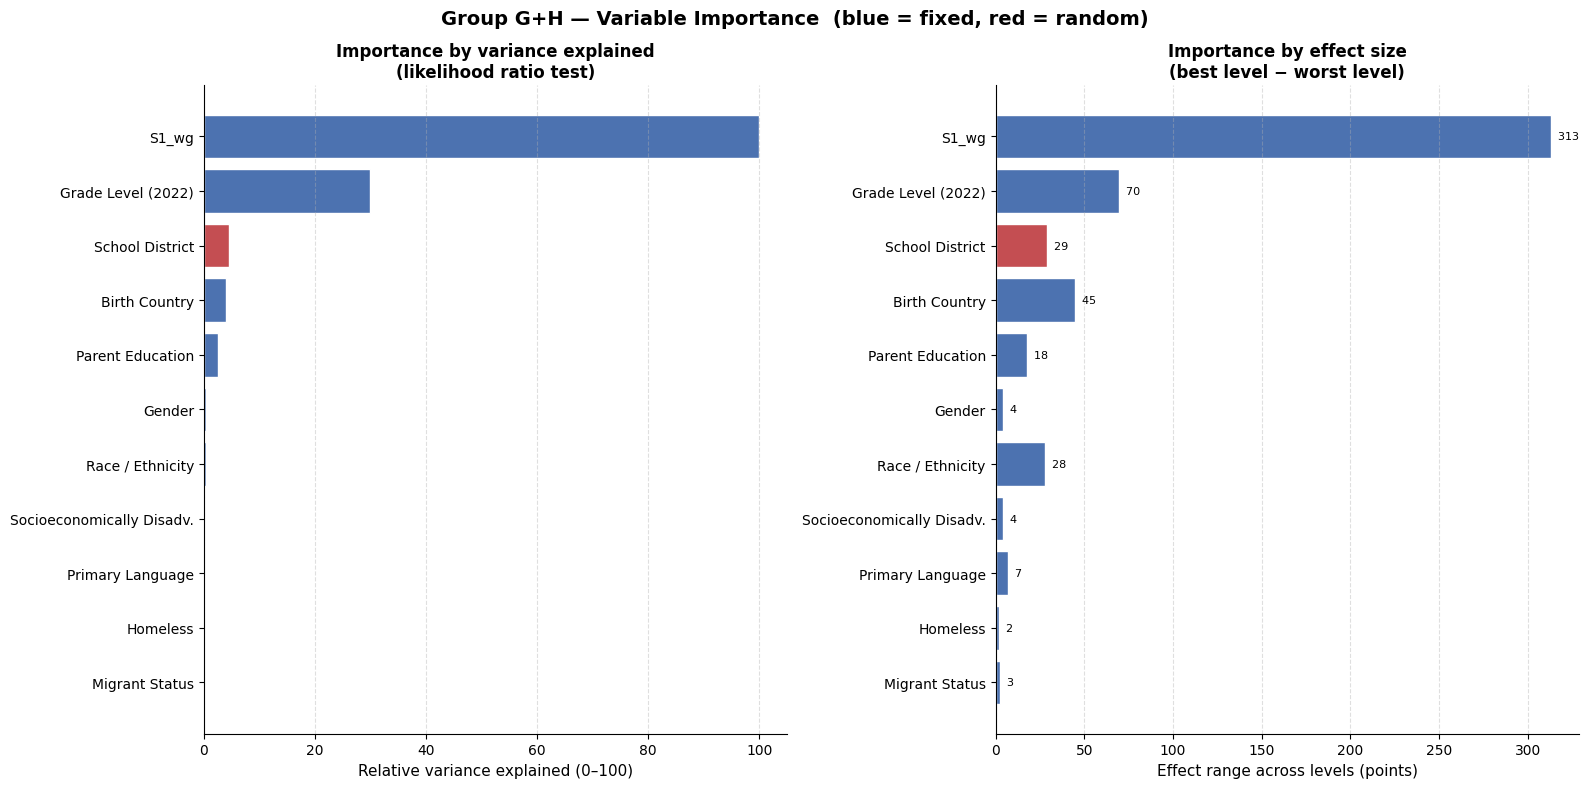

Saved: plots/group_gh_variable_importance.png


In [15]:
plot_df = imp.sort_values("Score_LRT", ascending=True)
colors = ["#C44E52" if t == "Random" else "#4C72B0" for t in plot_df["Type"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(plot_df["Label"], plot_df["Score_LRT"], color=colors, edgecolor="white")
axes[0].set_xlabel("Relative variance explained (0–100)", fontsize=11)
axes[0].set_title("Importance by variance explained\n(likelihood ratio test)",
                  fontsize=12, fontweight="bold")

axes[1].barh(plot_df["Label"], plot_df["EffectRange"], color=colors, edgecolor="white")
for i, (_, r) in enumerate(plot_df.iterrows()):
    axes[1].text(r["EffectRange"], i, f"  {r['EffectRange']:.0f}", va="center", fontsize=8)
axes[1].set_xlabel("Effect range across levels (points)", fontsize=11)
axes[1].set_title("Importance by effect size\n(best level − worst level)",
                  fontsize=12, fontweight="bold")

for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"{group_label} — Variable Importance  (blue = fixed, red = random)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"plots/{group_short}_variable_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_variable_importance.png")

In [16]:
# --- Per-level detail for the top fixed effects, with readable labels ---

# Label maps applied at display time only; the model still uses raw codes.
LEVEL_LABELS = {
    "BirthCountry": country_labels,
    # "Race": race_labels,   # already mapped at source in Cell 6
}

def prettify(e, varname):
    """Map coded levels to full names for display. Preserves '(ref)' markers."""
    lut = LEVEL_LABELS.get(varname)
    if lut is None:
        return e
    e = e.copy()

    def relabel(lvl):
        lvl = str(lvl)
        # var_effects marks the reference row as "XX (ref)" — map the code, keep the marker
        if lvl.endswith(" (ref)"):
            code = lvl[:-6]
            return f"{lut.get(code, code)} (ref)"
        return lut.get(lvl, lvl)

    e["Level"] = e["Level"].map(relabel)
    return e


for v in imp[imp["Type"] == "Fixed"]["Variable"].head(6):
    e = var_effects(v)
    if e is None:
        continue
    e = prettify(e, v)
    e = e.sort_values("Effect", ascending=False)
    print(f"\n{'='*72}\n{readable.get(v, v)}\n{'='*72}")
    print(e.to_string(index=False))

    # Flag any level that didn't find a label
    lut = LEVEL_LABELS.get(v)
    if lut is not None:
        unmapped = [l for l in e["Level"]
                    if l not in lut.values() and not l.endswith(" (ref)")]
        if unmapped:
            print(f"\n  NOTE: no label found for {unmapped} — add to country_labels in Cell 0")

re_df = pd.DataFrame([
    {"District": d, "Effect": float(np.asarray(val).ravel()[0])}
    for d, val in full_model.random_effects.items()
])
re_df["N"] = re_df["District"].map(model_df["District"].value_counts())
re_df = re_df.sort_values("Effect", ascending=False)
print(f"\n{'='*72}\nSchool District (shrunken random effects)\n{'='*72}")
print(re_df.to_string(index=False))

unit = "points" if OUTCOME == "ScoreGain" else "SD units"
print(f"\nICC = {icc:.4f}  |  district SD = {np.sqrt(vb):.2f} {unit}")


Grade Level (2022)
   Level  Effect    P       N
      02    8.23 0.00  913.00
01 (ref)    0.00  NaN 1257.00
      03  -24.87 0.00  866.00
      KN  -26.67 0.00 3576.00
      04  -30.39 0.00  830.00
      05  -31.35 0.00  708.00
      06  -46.32 0.00  721.00
      09  -47.53 0.00 1957.00
      11  -50.25 0.00   85.00
      10  -53.85 0.00  541.00
      07  -60.99 0.00  751.00
      08  -61.59 0.00  695.00

Birth Country
            Level  Effect    P       N
          Ukraine   17.02 0.00  203.00
           Russia   14.21 0.00  426.00
            Haiti   12.97 0.07   99.00
          Vietnam   12.40 0.01  188.00
          Armenia    8.96 0.03  477.00
   Other (pooled)    5.39 0.03 1266.00
            China    2.88 0.51  235.00
Afghanistan (ref)    0.00  NaN 2111.00
         Colombia  -10.97 0.03  258.00
           Mexico  -12.26 0.00 1780.00
        Nicaragua  -12.74 0.01  319.00
      El Salvador  -19.33 0.00 1863.00
         Honduras  -25.05 0.00  971.00
          Unknown  -25.24 0.0

In [17]:
# ==============================================================
# BIRTH COUNTRY × LANGUAGE — CONFOUNDING DIAGNOSTIC
# ==============================================================
# Two variables that encode nearly the same information cannot be
# interpreted individually in a joint model. This cell measures how
# much they overlap before we fit anything.

from scipy.stats import chi2_contingency

ct = pd.crosstab(model_df["BirthCountry"], model_df["Language"])
print("CROSS-TABULATION: Birth Country × Language")
print("=" * 62)
print(ct.to_string())

# --- Percent of each country that is Spanish-speaking ---
pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
print("\n\nPercent of each birth country by language:")
print("=" * 62)
print(pct.to_string())

# --- Cramér's V: 0 = independent, 1 = one perfectly predicts the other ---
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print("\n" + "=" * 62)
print(f"Cramér's V = {cramers_v:.4f}")
print(f"  chi2 = {chi2:,.1f}, dof = {dof}, p = {p:.2e}")
print("-" * 62)
if cramers_v > 0.7:
    print("SEVERE overlap — these variables encode nearly the same information.")
    print("Joint coefficients for BOTH are uninterpretable.")
elif cramers_v > 0.4:
    print("MODERATE overlap — joint coefficients are attenuated and unstable.")
else:
    print("MILD overlap — both can reasonably stay in the model.")
print("=" * 62)

# --- How cleanly does language partition the countries? ---
dominant = pct.idxmax(axis=1)
purity   = pct.max(axis=1)
print("\nDominant language per country (purity = % in that language):")
summary_ct = pd.DataFrame({
    "N": ct.sum(axis=1),
    "DominantLang": dominant,
    "Purity_%": purity.round(1),
}).sort_values("N", ascending=False)
print(summary_ct.to_string())

near_pure = (purity >= 95).sum()
print(f"\n{near_pure} of {len(purity)} countries are ≥95% one language.")
print("The higher this is, the more redundant the two variables are.")

CROSS-TABULATION: Birth Country × Language
Language      Non-Spanish  Spanish  Unknown
BirthCountry                               
AF                   2038        1       72
AM                    468        0        9
CN                    232        0        3
CO                      0      253        5
GT                    261     2246       31
HN                      2      955       14
HT                     74       25        0
MX                     15     1747       18
NI                      0      315        4
Other                1017      230       19
RU                    421        1        4
SV                      0     1836       27
UA                    201        0        2
UU                     25      136        5
VN                    187        0        1


Percent of each birth country by language:
Language      Non-Spanish  Spanish  Unknown
BirthCountry                               
AF                  96.50     0.00     3.40
AM                  98.10     0.

In [18]:
# ==============================================================
# FIT FOUR MODELS TO SEPARATE THE TWO EFFECTS
# ==============================================================
#   1. BOTH      — current specification
#   2. COUNTRY   — birth country only, language dropped
#   3. LANGUAGE  — language only, birth country dropped
#   4. NEITHER   — baseline for comparison
#
# ML (reml=False) is required: models with DIFFERENT fixed-effect
# sets have REML likelihoods that are not comparable.

specs = {
    "BOTH":     [t for t in fixed_cat],
    "COUNTRY":  [t for t in fixed_cat if t != "Language"],
    "LANGUAGE": [t for t in fixed_cat if t != "BirthCountry"],
    "NEITHER":  [t for t in fixed_cat if t not in ("BirthCountry", "Language")],
}

fits = {}
print("Fitting four models with ML...\n")
for name, terms in specs.items():
    f = build_formula(OUTCOME, BASELINE, terms)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm(f, data=model_df, groups="District").fit(
            reml=False, method="lbfgs", maxiter=2000)
    fits[name] = m
    print(f"  {name:<9} k={len(m.fe_params):>3}  logLik={m.llf:>12.2f}  "
          f"AIC={m.aic:>11.1f}  converged={m.converged}")

# --- Incremental contribution of each variable ---
print("\n" + "=" * 74)
print("INCREMENTAL CONTRIBUTION (likelihood ratio tests)")
print("=" * 74)

comparisons = [
    ("Language added to a model that already has Country",  "COUNTRY",  "BOTH"),
    ("Country added to a model that already has Language",  "LANGUAGE", "BOTH"),
    ("Country alone (vs neither)",                          "NEITHER",  "COUNTRY"),
    ("Language alone (vs neither)",                         "NEITHER",  "LANGUAGE"),
]

lrt_rows = []
for label, reduced, full in comparisons:
    lr  = 2 * (fits[full].llf - fits[reduced].llf)
    dfd = len(fits[full].fe_params) - len(fits[reduced].fe_params)
    pv  = sps.chi2.sf(lr, dfd) if dfd > 0 else np.nan
    lrt_rows.append({"Comparison": label, "chi2": lr, "df": dfd, "p": pv})
    print(f"\n{label}")
    print(f"   chi2 = {lr:>9.2f}   df = {dfd:>3}   p = {pv:.3e}"
          f"   {'SIGNIFICANT' if pv < 0.05 else 'not significant'}")

print("\n" + "=" * 74)
disentangle = pd.DataFrame(lrt_rows)

Fitting four models with ML...

  BOTH      k= 45  logLik=   -70418.20  AIC=   140930.4  converged=True
  COUNTRY   k= 43  logLik=   -70421.46  AIC=   140932.9  converged=True
  LANGUAGE  k= 31  logLik=   -70512.81  AIC=   141091.6  converged=True
  NEITHER   k= 29  logLik=   -70513.22  AIC=   141088.4  converged=True

INCREMENTAL CONTRIBUTION (likelihood ratio tests)

Language added to a model that already has Country
   chi2 =      6.53   df =   2   p = 3.828e-02   SIGNIFICANT

Country added to a model that already has Language
   chi2 =    189.22   df =  14   p = 8.654e-33   SIGNIFICANT

Country alone (vs neither)
   chi2 =    183.52   df =  14   p = 1.251e-31   SIGNIFICANT

Language alone (vs neither)
   chi2 =      0.82   df =   2   p = 6.635e-01   not significant



In [19]:
# ==============================================================
# COEFFICIENT SHIFT: joint model vs solo model
# ==============================================================
# A coefficient that changes substantially when the other variable
# is removed was absorbing that variable's effect.

def extract(model, prefix):
    p  = model.fe_params
    se = model.bse_fe
    pv = model.pvalues[p.index]
    m  = p.index.str.startswith(prefix)
    return pd.DataFrame({
        "Term":   p.index[m].str.extract(r"\[T\.(.+?)\]")[0].values,
        "Coef":   p[m].values,
        "SE":     se[m].values,
        "P":      pv[m].values,
    })

# --- Birth country ---
bc_both = extract(fits["BOTH"],    "C(BirthCountry)").set_index("Term")
bc_solo = extract(fits["COUNTRY"], "C(BirthCountry)").set_index("Term")

bc = bc_both.join(bc_solo, lsuffix="_joint", rsuffix="_solo")
bc["Shift"]    = bc["Coef_solo"] - bc["Coef_joint"]
bc["Shift_SE"] = bc["Shift"] / bc["SE_joint"]      # shift in standard-error units
bc["N"]        = model_df["BirthCountry"].value_counts()
bc = bc.sort_values("Coef_solo")

print("=" * 96)
print("BIRTH COUNTRY — coefficients with and without Language in the model")
print("=" * 96)
print(bc[["N", "Coef_joint", "P_joint", "Coef_solo", "P_solo", "Shift", "Shift_SE"]]
      .round(3).to_string())

# --- Language ---
lg_both = extract(fits["BOTH"],     "C(Language)").set_index("Term")
lg_solo = extract(fits["LANGUAGE"], "C(Language)").set_index("Term")

lg = lg_both.join(lg_solo, lsuffix="_joint", rsuffix="_solo")
lg["Shift"]    = lg["Coef_solo"] - lg["Coef_joint"]
lg["Shift_SE"] = lg["Shift"] / lg["SE_joint"]
lg["N"]        = model_df["Language"].value_counts()

print("\n" + "=" * 96)
print("LANGUAGE — coefficients with and without Birth Country in the model")
print("=" * 96)
print(lg[["N", "Coef_joint", "P_joint", "Coef_solo", "P_solo", "Shift", "Shift_SE"]]
      .round(3).to_string())

# --- Standard error inflation from collinearity ---
print("\n" + "=" * 96)
print("STANDARD ERROR INFLATION (joint ÷ solo — how much precision collinearity costs)")
print("=" * 96)
bc_infl = (bc["SE_joint"] / bc["SE_solo"]).sort_values(ascending=False)
print("\nBirth country:")
print(bc_infl.round(3).to_string())
print(f"\n  median inflation: {bc_infl.median():.3f}x   max: {bc_infl.max():.3f}x")

lg_infl = (lg["SE_joint"] / lg["SE_solo"])
print("\nLanguage:")
print(lg_infl.round(3).to_string())
print(f"\n  median inflation: {lg_infl.median():.3f}x   max: {lg_infl.max():.3f}x")

BIRTH COUNTRY — coefficients with and without Language in the model
          N  Coef_joint  P_joint  Coef_solo  P_solo  Shift  Shift_SE
Term                                                                
GT     2538      -27.61     0.00     -24.28    0.00   3.33      0.89
UU      166      -25.21     0.00     -22.08    0.00   3.13      0.56
HN      971      -25.03     0.00     -21.04    0.00   3.99      0.97
SV     1863      -19.30     0.00     -15.35    0.00   3.95      1.02
NI      319      -12.73     0.01      -8.75    0.06   3.98      0.82
MX     1780      -12.25     0.00      -8.37    0.02   3.88      1.01
CO      258      -10.94     0.03      -7.08    0.14   3.86      0.76
CN      235        2.89     0.51       3.00    0.49   0.12      0.03
Other  1266        5.42     0.03       6.04    0.02   0.63      0.25
AM      477        9.09     0.03       8.96    0.03  -0.13     -0.03
VN      188       12.47     0.01      12.45    0.01  -0.03     -0.01
HT       99       13.00     0.07   

In [20]:
# ==============================================================
# VERDICT
# ==============================================================
lang_given_country = disentangle.iloc[0]
country_given_lang = disentangle.iloc[1]
country_alone      = disentangle.iloc[2]
language_alone     = disentangle.iloc[3]

print("=" * 74)
print("DISENTANGLING BIRTH COUNTRY AND LANGUAGE — VERDICT")
print("=" * 74)
print(f"\nOverlap (Cramér's V):            {cramers_v:.3f}")
print(f"Country alone explains:          chi2 = {country_alone['chi2']:>8.1f} "
      f"(df {int(country_alone['df'])})")
print(f"Language alone explains:         chi2 = {language_alone['chi2']:>8.1f} "
      f"(df {int(language_alone['df'])})")
print(f"Country adds to Language:        chi2 = {country_given_lang['chi2']:>8.1f} "
      f"(p = {country_given_lang['p']:.2e})")
print(f"Language adds to Country:        chi2 = {lang_given_country['chi2']:>8.1f} "
      f"(p = {lang_given_country['p']:.2e})")

print(f"\nAIC — BOTH: {fits['BOTH'].aic:,.1f}   COUNTRY: {fits['COUNTRY'].aic:,.1f}   "
      f"LANGUAGE: {fits['LANGUAGE'].aic:,.1f}   NEITHER: {fits['NEITHER'].aic:,.1f}")
best = min(fits, key=lambda k: fits[k].aic)
print(f"Best by AIC: {best}")

print("\n" + "-" * 74)
if country_given_lang["p"] < 0.05 and lang_given_country["p"] >= 0.05:
    print("RECOMMENDATION: keep BIRTH COUNTRY, drop LANGUAGE.")
    print("Country adds real information beyond language; language adds none")
    print("beyond country. The positive Spanish coefficient in the joint model")
    print("was a residual artifact, not a finding.")
elif lang_given_country["p"] < 0.05 and country_given_lang["p"] >= 0.05:
    print("RECOMMENDATION: keep LANGUAGE, drop BIRTH COUNTRY.")
elif country_given_lang["p"] < 0.05 and lang_given_country["p"] < 0.05:
    print("RECOMMENDATION: both contribute independently — keep both, but")
    print("report them as a joint block rather than interpreting individual")
    print("coefficients, given the collinearity.")
else:
    print("RECOMMENDATION: neither adds much once the other is present.")
    print("Keep whichever is more interpretable for your audience.")
print("-" * 74)
print("\nReport SOLO coefficients for whichever variable you keep —")
print("the joint estimates are contaminated by the other.")
print("=" * 74)

DISENTANGLING BIRTH COUNTRY AND LANGUAGE — VERDICT

Overlap (Cramér's V):            0.644
Country alone explains:          chi2 =    183.5 (df 14)
Language alone explains:         chi2 =      0.8 (df 2)
Country adds to Language:        chi2 =    189.2 (p = 8.65e-33)
Language adds to Country:        chi2 =      6.5 (p = 3.83e-02)

AIC — BOTH: 140,930.4   COUNTRY: 140,932.9   LANGUAGE: 141,091.6   NEITHER: 141,088.4
Best by AIC: BOTH

--------------------------------------------------------------------------
RECOMMENDATION: both contribute independently — keep both, but
report them as a joint block rather than interpreting individual
coefficients, given the collinearity.
--------------------------------------------------------------------------

Report SOLO coefficients for whichever variable you keep —
the joint estimates are contaminated by the other.


# Group G+H Mixed-Effects Analysis: Results Summary (Scale-Score Points)

**Outcome:** Summative 2024 minus Summative 2022, in ELPAC Overall Scale Score points (`ScoreGain`)
**Baseline control:** each student's 2022 score, centered within grade (`S1_wg`)
**Model:** Linear mixed model with student characteristics as fixed effects and district as a random intercept
**Sample:** 12,900 of 12,918 students (99.9%) in 23 districts
**Average gain:** 103.5 points over two years (SD 73.1; range −235 to +472)

---

## Executive summary

1. **The model and the descriptive figures now agree.** With both expressed in scale-score points, the grade ranking from the model matches the observed ranking almost exactly (rank agreement 0.96) and follows the same order as the Figure 15 learning-rate chart. The earlier disagreement came from expressing the model in grade-standardized SD units and reporting it against a Grade 1 reference.

2. **Grade level is by far the strongest predictor of growth** (likelihood ratio χ² = 1,418, about seven times the next characteristic). Gains fall steadily with grade: students who began in Grades 1 and 2 gained the most (136 to 145 points observed), and students who began in Grades 7 and 8 gained the least (about 74 to 75 points).

3. **Kindergarten is not an outlier.** Kindergarten ranks 4th of 12 grades in both observed and adjusted gain and sits at the cohort average. The earlier finding that kindergarten was "well below baseline" was produced by the SD-unit metric and the Grade 1 comparison point, not by kindergartners' actual growth.

4. **Adjusting for student characteristics mostly confirms the raw picture, with one exception:** high school grades rise after adjustment (Grade 11 moves from 12th to 9th). Part of their lower observed growth is explained by who those students are rather than by grade itself.

5. **Districts differ in a real but modest way.** District accounts for 2.5% of the variation in growth, and the adjusted spread between the strongest and weakest district is about 29 points. Unadjusted district rankings largely reflect grade mix: a district's expected gain correlates +0.70 with its share of K to 5 students. Twin Rivers drops from 6th observed to 22nd adjusted, and Cajon Valley from 3rd to 11th, because their young students were expected to grow fast; Los Angeles County Office of Education rises from 15th to 2nd and Modesto City High from 20th to 9th.

6. **Country of birth shows the largest demographic gap** (about 45 points adjusted). Central American and Mexican origin groups grow least and Eastern European origin groups most. This ordering is identical whether measured in points or SD units.

7. **Parent education matters at the high school line.** Students whose parents have a high school education or less, or whose parents' education is unreported, gained about 14 to 17 points less than students whose parents hold a graduate degree. College-educated families and those with some college did not differ from graduate-degree families.

8. **Several large observed gaps shrink or vanish after adjustment.** The socioeconomic gap falls from 13.3 points observed to 4.4 adjusted. The 21-point White versus Hispanic/Latino gap falls to about 4 points and is not significant. The 14-point disadvantage for Spanish speakers reverses entirely once country of birth is accounted for.

9. **Only grade is sensitive to the choice of metric.** Grade rankings agree poorly between points and SD units (rank correlation 0.29), while every other characteristic agrees closely (0.83 to 1.00). Conclusions about country, district, parent education, race, and language do not depend on the metric.

---

## Notebook issues to resolve before reporting

**1. Parent education labels are reversed (Cell 6).** CALPADS codes run in descending order (10 = graduate degree or higher, 14 = not a high school graduate). Cell 6 still uses the earlier ascending map, so every ParentEd label in Cells 6, 8, 12, 14, and 22 is wrong. Because the map merged codes 13 and 14, which are adjacent, the model results are still valid once relabeled:

| Label in notebook | CALPADS codes | Correct meaning | Students |
|---|---|---|---|
| `1_NotHSGrad` | 10 | Graduate degree or higher | 800 |
| `2_HSGrad` | 11 | College graduate | 1,168 |
| `3_SomeCollege` | 12 | Some college or associate degree | 688 |
| `4_CollegePlus` | 13 + 14 | High school graduate or less | 5,459 |
| `5_Declined` | 15 | Declined to state or unknown | 4,728 |
| `Missing` | blank | Not recorded | 57 |

This summary uses the correct meanings. To fix the notebook, replace `parent_ed_map` in Cell 6 with the descending map and rerun; that also separates high school graduates from non-graduates.

**2. "Adjusted" values in Cell A sit about 4.3 points low.** The adjusted predictions include fixed effects only, which places them at an unweighted average district. Because Los Angeles Unified (42% of students) has a +12.2 district effect, the student-weighted average is about 4.3 points higher. Rankings and gaps between levels are unaffected, so **compare adjusted values with each other, not directly with observed values**, until this is fixed. In `observed_vs_adjusted`, replace the line that computes `adj[lvl]` with:

```python
re_map = {d: float(np.asarray(v).ravel()[0]) for d, v in model.random_effects.items()}
blup = data["District"].map(re_map).fillna(0).to_numpy()
adj[lvl] = float(np.mean(model.predict(cf).to_numpy() + blup))
```

The district table (Cell B) is not affected.

**3. Two verdict messages are out of date.** Cell 9 still compares the old cohort-centered model and tells the reader the raw-point ranking is "a scaling artifact"; Cell 3 prints a similar verdict. Both contradict the specification now in use and should be removed or reworded. Cell 12 also labels the baseline row `S1_wg` rather than a readable name.

---

## 1. Why this specification

The Summative ELPAC is reported on a vertical scale designed for comparing growth across grade levels, so scale-score points are a legitimate common metric and match the units of the descriptive figures. The baseline score is centered within each grade so that it controls for where a student stood relative to grade peers without absorbing real differences between grades.

A useful technical consequence: because `S1_wg` differs from the cohort-centered baseline only by a constant within each grade, and the model already contains grade indicators, **every non-grade coefficient is identical** to the earlier raw-point model. Only the grade coefficients change.

---

## 2. Model fit and variance

| Quantity | Value |
|---|---|
| Converged | Yes (REML) |
| Between-district variance | 83.56 (SD 9.14 points) |
| Within-district variance | 3,227.14 (SD 56.81 points) |
| Intraclass correlation | 0.0252 (2.52% of variation between districts) |
| District likelihood ratio test | χ² = 215.0, p = 5.5 × 10⁻⁴⁹ (halved for boundary; unhalved p = 1.1 × 10⁻⁴⁸) |

---

## 3. Variable importance

Likelihood ratio tests from dropping each characteristic in turn (ML fits). The 2022 baseline (χ² = 4,721) is omitted because the outcome is constructed by subtracting it.

| Rank | Characteristic | χ² | Raw p | Bonferroni | BH-FDR |
|---|---|---|---|---|---|
| 1 | Grade level | 1,417.7 | < 0.001 | ✓ | ✓ |
| 2 | School district | 215.0 | < 0.001 | ✓ | ✓ |
| 3 | Country of birth | 189.2 | < 0.001 | ✓ | ✓ |
| 4 | Parent education | 120.7 | < 0.001 | ✓ | ✓ |
| 5 | Gender | 16.7 | < 0.001 | ✓ | ✓ |
| 6 | Race and ethnicity | 16.3 | 0.023 | ✗ | ✓ |
| 7 | Socioeconomically disadvantaged | 11.7 | < 0.001 | ✓ | ✓ |
| 8 | Primary language | 6.5 | 0.038 | ✗ | ✓ |
| 9 | Homeless program | 1.3 | 0.248 | ✗ | ✗ |
| 10 | Migrant status | 0.3 | 0.615 | ✗ | ✗ |

Nine characteristics are significant at p < 0.05 and seven survive Bonferroni correction. Race and ethnicity and primary language should be treated as suggestive.

Compared with the SD-unit model, grade's χ² rose from 376 to 1,418 and district moved from fourth to second, above country of birth.

---

## 4. Grade level

Rank agreement between observed and adjusted: **0.96.**

| Grade (2022) | Students | Observed gain | Adjusted gain* | Observed rank | Adjusted rank | Model coefficient vs Grade 1 |
|---|---|---|---|---|---|---|
| Grade 2 | 913 | 145.3 | 138.8 | 1 | 1 | +8.2 |
| Grade 1 | 1,257 | 136.4 | 130.6 | 2 | 2 | 0 (reference) |
| Grade 3 | 866 | 113.7 | 105.7 | 3 | 3 | −24.9 |
| Kindergarten | 3,576 | 108.3 | 103.9 | 4 | 4 | −26.7 |
| Grade 4 | 830 | 108.1 | 100.2 | 5 | 5 | −30.4 |
| Grade 5 | 708 | 105.6 | 99.2 | 6 | 6 | −31.4 |
| Grade 6 | 721 | 90.7 | 84.3 | 7 | 7 | −46.3 |
| Grade 9 | 1,957 | 81.8 | 83.1 | 8 | 8 | −47.5 |
| Grade 11 | 85 | 74.1 | 80.3 | 12 | 9 | −50.3 |
| Grade 10 | 541 | 75.6 | 76.7 | 9 | 10 | −53.8 |
| Grade 7 | 751 | 75.1 | 69.6 | 10 | 11 | −61.0 |
| Grade 8 | 695 | 74.2 | 69.0 | 11 | 12 | −61.6 |

\*Adjusted values sit about 4.3 points low; see Notebook issue 2. All coefficients p < 0.001.

**Reading the results.** Growth declines steadily from the early grades to the middle grades: students who began in Grades 1 and 2 gained roughly twice as many points as students who began in Grades 7 and 8. The adjusted spread from Grade 2 to Grade 8 is about 70 points.

**Kindergarten** gained 108 points, 4th of 12 grades and at the cohort average, in both observed and adjusted terms. After the 4.3-point offset is restored, kindergarten's adjusted gain is essentially identical to its observed gain, meaning other characteristics explain almost nothing about its position.

**High school** is where adjustment matters. Restoring the offset, Grades 9 through 11 rise about 5 to 10 points after adjustment, while elementary and middle grades change by 4 points or less. Grade 11 moves from last to 9th. The lowest adjusted growth belongs to Grades 7 and 8, not to high school.

---

## 5. Country of birth

Rank agreement between observed and adjusted: **0.73.** Reference for coefficients: Afghanistan.

| Country | Students | Observed gain | Adjusted gain* | Observed rank | Adjusted rank |
|---|---|---|---|---|---|
| Ukraine | 203 | 130.9 | 126.9 | 2 | 1 |
| Russia | 426 | 140.0 | 124.1 | 1 | 2 |
| Haiti | 99 | 110.5 | 122.9 | 7 | 3 |
| Vietnam | 188 | 105.5 | 122.3 | 8 | 4 |
| Armenia | 477 | 118.3 | 118.9 | 4 | 5 |
| Other (pooled) | 1,266 | 103.9 | 115.3 | 10 | 6 |
| China | 235 | 94.1 | 112.8 | 12 | 7 |
| Afghanistan | 2,111 | 117.3 | 109.9 | 5 | 8 |
| Colombia | 258 | 120.4 | 98.9 | 3 | 9 |
| Mexico | 1,780 | 104.3 | 97.6 | 9 | 10 |
| Nicaragua | 319 | 112.2 | 97.2 | 6 | 11 |
| El Salvador | 1,863 | 98.1 | 90.6 | 11 | 12 |
| Honduras | 971 | 90.8 | 84.9 | 13 | 13 |
| Unknown | 166 | 77.7 | 84.7 | 15 | 14 |
| Guatemala | 2,538 | 88.3 | 82.3 | 14 | 15 |

\*Adjusted values sit about 4.3 points low; see Notebook issue 2.

The adjusted spread from Ukraine to Guatemala is about 45 points, the largest demographic gap in the study. Every Central American and Mexican origin group falls in the bottom seven; Eastern European origin groups lead. Significant coefficients relative to Afghanistan: Ukraine +17.0, Russia +14.2, Vietnam +12.4, Armenia +9.0, Other +5.4; Colombia −11.0, Mexico −12.3, Nicaragua −12.7, El Salvador −19.3, Honduras −25.1, Unknown −25.2, Guatemala −27.6. Haiti (+13.0, p = 0.07) and China (+2.9, p = 0.51) are not significant.

Several countries move substantially between observed and adjusted, mostly reflecting grade mix: Colombia (3rd to 9th) and Nicaragua (6th to 11th) fall, while China (12th to 7th), Vietnam (8th to 4th), and Haiti (7th to 3rd) rise.

---

## 6. School district

Rank agreement between observed gain and district effect is modest; the reordering is driven by what each district's students were expected to gain.

| District | Students | % in K to 5 | Most common birth country | Observed | Expected given its students | Observed minus expected | District effect (shrunken) | Observed rank | Adjusted rank |
|---|---|---|---|---|---|---|---|---|---|
| Glendale Unified | 523 | 68.1 | Armenia | 125.6 | 111.4 | +14.2 | +13.2 | 2 | 1 |
| LA County Office of Education | 42 | 28.6 | Guatemala | 94.5 | 70.1 | +24.5 | +12.7 | 15 | 2 |
| Los Angeles Unified | 5,397 | 57.8 | Guatemala | 102.8 | 90.4 | +12.3 | +12.2 | 11 | 3 |
| Mt. Diablo Unified | 305 | 71.8 | Afghanistan | 129.5 | 121.1 | +8.4 | +7.4 | 1 | 4 |
| Mendota Unified | 117 | 68.4 | El Salvador | 103.2 | 93.9 | +9.3 | +7.0 | 10 | 5 |
| San Diego Unified | 817 | 66.2 | Afghanistan | 116.5 | 109.5 | +7.1 | +6.8 | 4 | 6 |
| Garden Grove Unified | 227 | 67.4 | Vietnam | 104.6 | 96.8 | +7.8 | +6.7 | 8 | 7 |
| San Rafael City Elementary | 128 | 80.5 | Guatemala | 98.1 | 90.5 | +7.7 | +5.9 | 13 | 8 |
| Modesto City High | 27 | 0.0 | Afghanistan | 84.4 | 76.0 | +8.4 | +3.4 | 20 | 9 |
| San Juan Unified | 915 | 73.3 | Afghanistan | 113.4 | 113.4 | 0.0 | 0.0 | 5 | 10 |
| Cajon Valley Union | 496 | 81.5 | Afghanistan | 119.2 | 120.2 | −1.1 | −1.0 | 3 | 11 |
| Fresno Unified | 231 | 72.3 | Mexico | 103.9 | 105.1 | −1.1 | −1.0 | 9 | 12 |
| Modesto City Elementary | 183 | 85.8 | Mexico | 106.6 | 108.9 | −2.4 | −2.0 | 7 | 13 |
| Elk Grove Unified | 379 | 72.3 | Afghanistan | 95.8 | 98.2 | −2.4 | −2.2 | 14 | 14 |
| Alvord Unified | 80 | 68.8 | Mexico | 93.8 | 97.0 | −3.3 | −2.2 | 16 | 15 |
| Hayward Unified | 304 | 65.5 | El Salvador | 102.7 | 106.1 | −3.4 | −3.0 | 12 | 16 |
| Santa Ana Unified | 269 | 67.3 | Mexico | 91.2 | 94.8 | −3.6 | −3.2 | 17 | 17 |
| San Francisco Unified | 441 | 45.8 | China | 73.5 | 78.5 | −5.0 | −4.6 | 21 | 18 |
| San Rafael City High | 66 | 0.0 | Guatemala | 64.0 | 72.3 | −8.3 | −5.2 | 23 | 19 |
| Oakland Unified | 762 | 65.1 | Guatemala | 86.0 | 95.6 | −9.5 | −9.1 | 19 | 20 |
| West Contra Costa Unified | 409 | 70.9 | Guatemala | 87.0 | 101.2 | −14.2 | −13.0 | 18 | 21 |
| Twin Rivers Unified | 707 | 66.2 | Afghanistan | 108.1 | 121.9 | −13.8 | −13.0 | 6 | 22 |
| Grossmont Union High | 75 | 0.0 | Afghanistan | 67.7 | 91.8 | −24.1 | −15.9 | 22 | 23 |

**How to read it.** "Expected" is what a district's own students would gain in an average district, given their grades, countries of birth, parent education, and other characteristics. The district's contribution is the gap between observed and expected; the shrunken district effect is that same gap after the model moderates estimates for small districts.

**Grade mix drives the unadjusted ranking.** A district's expected gain correlates **+0.70** with its share of K to 5 students. High-school-only districts (Grossmont Union High, San Rafael City High, Modesto City High) have low observed gains largely because their students are older.

**Biggest movers:**

- **Twin Rivers Unified** gained 108 points, 6th observed, but its students were expected to gain 122, so its adjusted effect is −13.0 (22nd).
- **Cajon Valley Union** (81.5% K to 5) gained 119 points, 3rd observed, but that is what its young students were expected to gain (11th adjusted).
- **Los Angeles County Office of Education** gained only 94.5 points but was expected to gain 70.1 (28.6% K to 5, mostly from Guatemala), placing it 2nd adjusted. With 42 students, its effect is shrunk by half.
- **Modesto City High** rises from 20th to 9th for the same reason, on only 27 students.

The adjusted range runs from Glendale Unified (+13.2) to Grossmont Union High (−15.9), about 29 points. District accounts for 2.5% of the variation in growth; the remaining 97.5% lies between students within the same district.

---

## 7. Parent education (corrected labels)

Rank agreement between observed and adjusted: **0.83.** Reference for coefficients: graduate degree or higher.

| Parent education | Students | Observed gain | Adjusted gain* | Coefficient | p |
|---|---|---|---|---|---|
| Graduate degree or higher | 800 | 113.0 | 111.5 | 0 (reference) | |
| Some college or associate degree | 688 | 116.9 | 111.2 | −0.3 | 0.913 |
| College graduate | 1,168 | 114.7 | 111.0 | −0.5 | 0.852 |
| High school graduate or less | 5,459 | 101.5 | 97.2 | −14.3 | < 0.001 |
| Declined to state or unknown | 4,728 | 99.6 | 94.7 | −16.8 | < 0.001 |
| Not recorded | 57 | 88.5 | 93.9 | −17.7 | 0.042 |

\*Adjusted values sit about 4.3 points low; see Notebook issue 2.

Families with any postsecondary education are indistinguishable from one another. Students whose parents have a high school education or less gained about 14 points less, and the declined-to-state or unknown group, which CALPADS also uses when education is not known, gained about 17 points less. The effect holds after controlling for socioeconomic status, country of birth, grade, and district.

---

## 8. Other characteristics

**Race and ethnicity** (χ² = 16.3; fails Bonferroni). Reference: Hispanic/Latino (8,002 students).

| Group | Students | Observed | Adjusted* | Coefficient | p |
|---|---|---|---|---|---|
| Two or More Races | 91 | 145.1 | 111.5 | +14.0 | 0.039 |
| Asian | 1,923 | 111.5 | 103.7 | +6.2 | 0.071 |
| White | 2,107 | 118.4 | 101.6 | +4.1 | 0.208 |
| Not Reported | 475 | 113.0 | 101.6 | +4.1 | 0.271 |
| Filipino | 78 | 78.1 | 101.5 | +4.0 | 0.579 |
| Pacific Islander | 47 | 101.7 | 101.2 | +3.7 | 0.675 |
| Hispanic/Latino | 8,002 | 97.1 | 97.5 | 0 (reference) | |
| Black | 177 | 91.2 | 83.6 | −13.9 | 0.014 |

The 21-point observed gap between White and Hispanic/Latino students shrinks to 4 points after adjustment and is not significant; country of birth accounts for most of it.

**Gender.** Female 105.4 observed, male 101.8. Adjusted difference: males −4.1 points (p < 0.001). Small and consistent across every version of the analysis.

**Socioeconomically disadvantaged.** Not disadvantaged 113.7 observed, disadvantaged 100.4: a 13.3-point gap. Adjusted difference: −4.4 points (p = 0.001). Two thirds of the observed gap is explained by other characteristics.

**Primary language.** Observed: Spanish speakers 97.9, non-Spanish 111.9. Adjusted coefficient for Spanish: **+6.8** (p = 0.013). The observed disadvantage reverses after adjustment because country of birth explains it; see Section 9.

**Homeless program** (−2.0, p = 0.244) and **migrant status** (−2.8, p = 0.608) show no detectable effect. Homeless students' observed gain (104.8) was slightly above that of non-homeless students (103.3).

---

## 9. Birth country and primary language

The two variables overlap heavily (Cramér's V = 0.644; 11 of 15 countries are at least 95% one language).

| Test | χ² | df | p |
|---|---|---|---|
| Country alone | 183.5 | 14 | < 0.001 |
| Language alone | 0.8 | 2 | 0.664 |
| Country added to language | 189.2 | 14 | < 0.001 |
| Language added to country | 6.5 | 2 | 0.038 |

Language alone predicts nothing. The Spanish coefficient is +6.8 with country in the model and −0.9 (p = 0.70) without it, a shift of 2.85 standard errors. AIC slightly favors keeping both (140,930.4 versus 140,932.9 for country only). The Spanish coefficient is therefore a **within-country** contrast: in countries with mixed language populations, mainly Guatemala (88.5% Spanish, 10.3% other, largely indigenous languages), Haiti, and the pooled Other group, students whose primary language is not Spanish gained less than Spanish-speaking students from the same country. It should not be reported as a general Spanish-speaker effect.

---

## 10. Robustness: points versus SD units

The same model was refit with grade-standardized SD units (`ZGain_fixed`, baseline `Z1_fixed`) and the adjusted rankings compared.

| Characteristic | Levels | Rank agreement | Levels moving 3+ places |
|---|---|---|---|
| Grade | 12 | 0.29 | Grade 2 (1 to 6); Grade 1 (2 to 8); Kindergarten (4 to 10); Grade 4 (5 to 1); Grade 9 (8 to 2); Grade 11 (9 to 3) |
| Parent education | 6 | 0.83 | none |
| Race and ethnicity | 8 | 0.95 | none |
| Country of birth | 15 | 1.00 | none |
| Primary language | 3 | 1.00 | none |
| School district | 23 | 0.99 | (see Section 6) |

**Grade is the only metric-sensitive result.** In points, early grades grow most; in SD units, Grades 4 and 9 lead because early grades have much wider score spreads (2022 SD of 78 to 87 points in K to 2, versus 48 to 63 in Grades 7 to 11). Findings that hold under both metrics: Grades 7 and 8 are among the slowest-growing grades, and the country, district, parent education, race, and language results are unchanged.

---

## 11. Changes from the SD-unit summary

| Finding | SD-unit model (previous) | Points model (current) |
|---|---|---|
| Fastest-growing grades | Grades 4 and 9 | Grades 2 and 1 |
| Kindergarten | Below Grade 1 by 0.18 SD; 10th of 12 | 108 points; 4th of 12; at cohort average |
| Slowest-growing grades | Grades 10 and 8 | Grades 8 and 7 |
| Grade χ² | 376 | 1,418 |
| Rank of district among predictors | 4th | 2nd |
| ICC | 2.31% | 2.52% |
| Country, parent education, race, language | (same ordering) | (same ordering) |

Report text that depends on the old metric, including statements that upper elementary students progress fastest and that kindergarten is well below average, should be revised to the points results.

---

## 12. Limitations

- **Associations, not causes.** Students were not randomly assigned to grades, districts, or circumstances.
- **Unmeasured factors** such as attendance, program model, instructional minutes, prior schooling, and services received are not in the data.
- **Demographics are measured once**, in 2021-22.
- **The cohort is selective:** students with three consecutive years of records. Students who moved, stopped testing, or were reclassified are not represented.
- **Cross-grade point comparisons** rely on the ELPAC vertical scale; CDE advises caution when comparing nonadjacent grade levels.
- **Statistical significance is not practical significance.** With nearly 13,000 students, effects of 4 points are detectable.


In [21]:
# --- What are the actual RaceEthnicity codes? ---
print("RaceEthnicity in the FULL enrollment file (not just G+H):")
print(enrollment["RaceEthnicity"].value_counts(dropna=False).to_string())

print("\n\nCross-check against the component race fields:")
xtab = (
    enrollment[["RaceEthnicity", "StudentHispanicEthnicityIndicator", "StudentRace1Code"]]
    .astype(str).apply(lambda c: c.str.strip())
    .value_counts()
    .reset_index(name="N")
    .sort_values(["RaceEthnicity", "N"], ascending=[True, False])
)
for code in sorted(xtab["RaceEthnicity"].unique()):
    sub = xtab[xtab["RaceEthnicity"] == code].head(3)
    print(f"\n  RaceEthnicity = '{code}'  (total {sub['N'].sum():,}+)")
    for _, r in sub.iterrows():
        print(f"    Hispanic={r['StudentHispanicEthnicityIndicator']:<6} "
              f"Race1={r['StudentRace1Code']:<6} n={r['N']:,}")

RaceEthnicity in the FULL enrollment file (not just G+H):
RaceEthnicity
H    914672
W    224835
A    127842
B    122586
T     57180
F     32290
D     28469
P      7835
I      3909


Cross-check against the component race fields:

  RaceEthnicity = 'A'  (total 84,155+)
    Hispanic=N      Race1=201.0  n=30,882
    Hispanic=N      Race1=204.0  n=27,639
    Hispanic=N      Race1=299.0  n=25,634

  RaceEthnicity = 'B'  (total 122,273+)
    Hispanic=N      Race1=600.0  n=122,273

  RaceEthnicity = 'F'  (total 30,879+)
    Hispanic=N      Race1=400.0  n=29,415
    Hispanic=N      Race1=201.0  n=992
    Hispanic=N      Race1=299.0  n=472

  RaceEthnicity = 'H'  (total 630,628+)
    Hispanic=Y      Race1=700.0  n=532,608
    Hispanic=Y      Race1=100.0  n=76,395
    Hispanic=Y      Race1=600.0  n=21,625

  RaceEthnicity = 'I'  (total 3,866+)
    Hispanic=N      Race1=100.0  n=3,866

  RaceEthnicity = 'P'  (total 7,359+)
    Hispanic=N      Race1=399.0  n=5,009
    Hispanic=N      Race1=303.0  

In [22]:
# =============================================================================
# Observed vs. adjusted growth, on one metric
# For: Group_G_H_mixed_effects_HLM.ipynb
#
# Purpose: make the HLM tables and the descriptive figures use the SAME units
# (vertically scaled ELPAC scale-score points), and present each characteristic
# as "observed gain" next to "adjusted gain" instead of contrasts against a
# reference category.
#
# SETUP (two small edits to existing cells, then Restart and Run All):
#
#   Cell 0, change the outcome switch to:
#       OUTCOME  = "ScoreGain"
#       BASELINE = "S1_wg"
#
#   Cell 6, add this line right after work["Grade"] is created:
#       work["S1_wg"] = work["Summ1Score"] - work.groupby("Grade")["Summ1Score"].transform("mean")
#
#   Why S1_wg: the starting score is centered WITHIN each grade, so the
#   baseline control adjusts for where a student stands relative to grade
#   peers without absorbing the real differences between grades. The earlier
#   raw-point model centered on the cohort mean, and because older grades
#   start higher, its baseline term soaked up much of the grade effect.
#
# After the rerun, every existing table (6 through 10) is in points.
# Then paste the four cells below after Cell 8 (the model fit).
# =============================================================================

In [23]:
# %% [Cell A] Observed vs adjusted gain for every characteristic
import numpy as np
import pandas as pd
import warnings
import statsmodels.formula.api as smf

assert OUTCOME == "ScoreGain" and BASELINE == "S1_wg", "Make the Cell 0 edit first (see header)."

GRADE_LABELS = {"KN": "Kindergarten", **{f"{g:02d}": f"Grade {g}" for g in range(1, 13)}}

def pretty(var, lvl):
    if var == "Grade":
        return GRADE_LABELS.get(lvl, lvl)
    if var == "BirthCountry":
        return country_labels.get(lvl, lvl)
    return lvl

def observed_vs_adjusted(model, data, var, outcome):
    """
    Observed: the group's actual mean gain.
    Adjusted: the average predicted gain if every student in the cohort belonged
              to this group, with everything else about them unchanged
              (g-computation). Same units as Observed, and no reference category.
    """
    obs = data.groupby(var)[outcome].agg(Students="size", Observed="mean")
    adj = {}
    for lvl in obs.index:
        cf = data.copy()
        cf[var] = lvl
        adj[lvl] = float(np.mean(model.predict(cf)))
    out = obs.assign(Adjusted=pd.Series(adj)).reset_index()
    out["Label"] = [pretty(var, l) for l in out[var]]
    out["Rank_obs"] = out["Observed"].rank(ascending=False, method="min").astype(int)
    out["Rank_adj"] = out["Adjusted"].rank(ascending=False, method="min").astype(int)
    return out.sort_values("Adjusted", ascending=False).reset_index(drop=True)

oa = {}
for var in model_cats:
    t = observed_vs_adjusted(full_model, model_df, var, OUTCOME)
    oa[var] = t
    rho = t["Observed"].corr(t["Adjusted"], method="spearman") if len(t) > 2 else float("nan")
    print(f"\n{'=' * 80}\n{var}   (rank agreement, observed vs adjusted: rho = {rho:+.2f})\n{'=' * 80}")
    print(t[["Label", "Students", "Observed", "Adjusted", "Rank_obs", "Rank_adj"]]
          .round(1).to_string(index=False))
    t.to_csv(f"obs_vs_adj_{group_short}_{var}.csv", index=False)

print(f"\nCohort mean gain: {model_df[OUTCOME].mean():.1f} points")



Grade   (rank agreement, observed vs adjusted: rho = +0.96)
       Label  Students  Observed  Adjusted  Rank_obs  Rank_adj
     Grade 2       913    145.30    138.80         1         1
     Grade 1      1257    136.40    130.60         2         2
     Grade 3       866    113.70    105.70         3         3
Kindergarten      3576    108.30    103.90         4         4
     Grade 4       830    108.10    100.20         5         5
     Grade 5       708    105.60     99.20         6         6
     Grade 6       721     90.70     84.30         7         7
     Grade 9      1957     81.80     83.10         8         8
    Grade 11        85     74.10     80.30        12         9
    Grade 10       541     75.60     76.70         9        10
     Grade 7       751     75.10     69.60        10        11
     Grade 8       695     74.20     69.00        11        12

ParentEd   (rank agreement, observed vs adjusted: rho = +0.83)
        Label  Students  Observed  Adjusted  Rank_obs  R

In [24]:
# %% [Cell B] District: observed, expected given its students, and the district effect
# Expected = what this district's own students would gain in an average district,
# given their grades, countries, parent education, and so on. The gap between
# Observed and Expected is the district's contribution; District_effect is the
# same quantity after the model's shrinkage of small districts.

model_df["_expected"] = full_model.predict(model_df)   # fixed effects only: average district
re_pts = {d: float(np.asarray(v).ravel()[0]) for d, v in full_model.random_effects.items()}
ELEM = ["KN", "01", "02", "03", "04", "05"]

dist = (model_df.groupby("District")
        .agg(Students=(OUTCOME, "size"),
             Observed=(OUTCOME, "mean"),
             Expected=("_expected", "mean"),
             Pct_K5=("Grade", lambda s: 100 * s.isin(ELEM).mean()),
             Top_country=("BirthCountry", lambda s: pretty("BirthCountry", s.mode().iat[0])))
        .reset_index())
dist["Obs_minus_Exp"] = dist["Observed"] - dist["Expected"]
dist["District_effect"] = dist["District"].map(re_pts)
dist["Adjusted"] = model_df[OUTCOME].mean() + dist["District_effect"]
dist["Label"] = dist["District"]
dist["Rank_obs"] = dist["Observed"].rank(ascending=False, method="min").astype(int)
dist["Rank_adj"] = dist["District_effect"].rank(ascending=False, method="min").astype(int)
dist = dist.sort_values("District_effect", ascending=False).reset_index(drop=True)

print(dist[["District", "Students", "Pct_K5", "Top_country", "Observed", "Expected",
            "Obs_minus_Exp", "District_effect", "Rank_obs", "Rank_adj"]].round(1).to_string(index=False))
print(f"\nCorrelation between a district's Expected gain and its share of K-5 students: "
      f"{dist['Expected'].corr(dist['Pct_K5']):+.2f}")
print("A strong positive value confirms that grade mix drives the unadjusted district ranking.")
dist.to_csv(f"obs_vs_adj_{group_short}_District.csv", index=False)


                              District  Students  Pct_K5 Top_country  Observed  Expected  Obs_minus_Exp  District_effect  Rank_obs  Rank_adj
                      Glendale Unified       523   68.10     Armenia    125.60    111.40          14.20            13.20         2         1
Los Angeles County Office of Education        42   28.60   Guatemala     94.50     70.10          24.50            12.70        15         2
                   Los Angeles Unified      5397   57.80   Guatemala    102.80     90.40          12.30            12.20        11         3
                    Mt. Diablo Unified       305   71.80 Afghanistan    129.50    121.10           8.40             7.40         1         4
                       Mendota Unified       117   68.40 El Salvador    103.20     93.90           9.30             7.00        10         5
                     San Diego Unified       817   66.20 Afghanistan    116.50    109.50           7.10             6.80         4         6
             

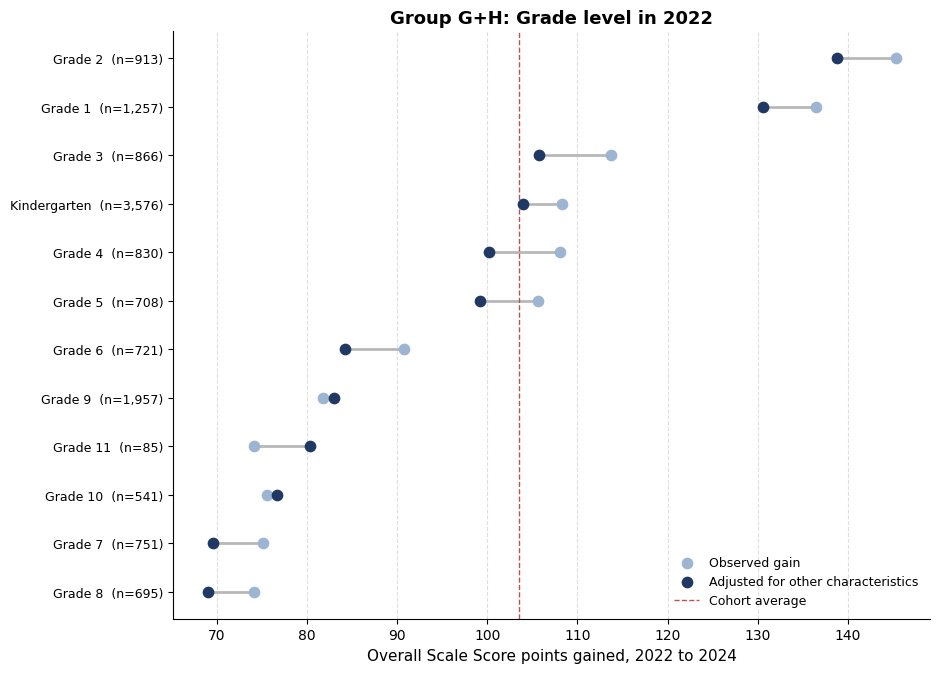

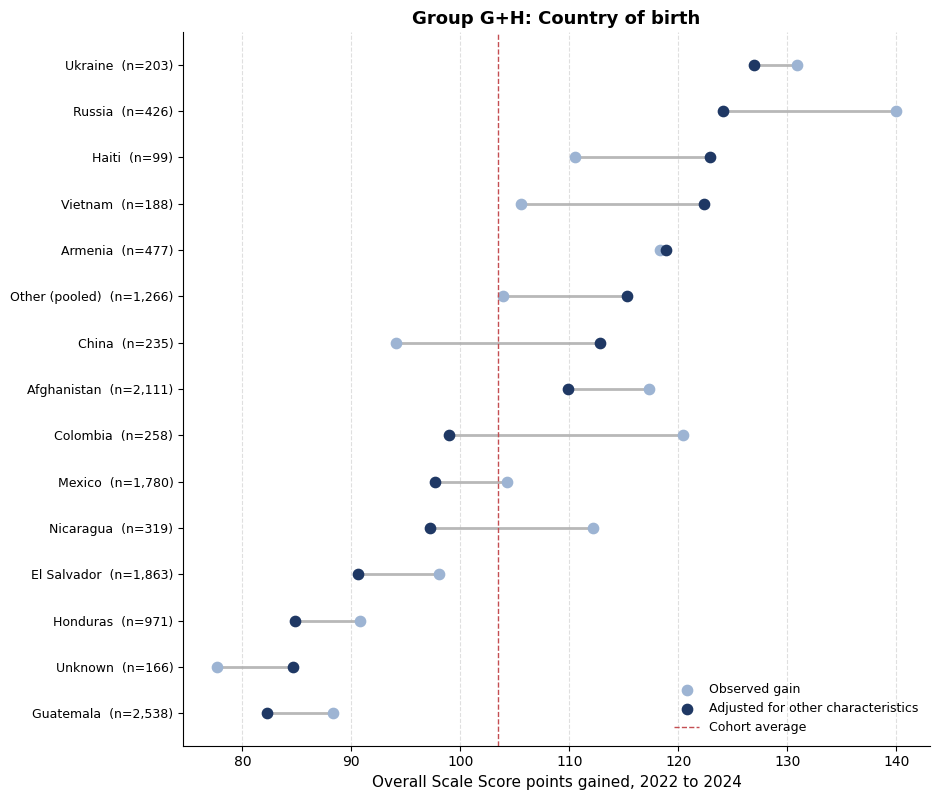

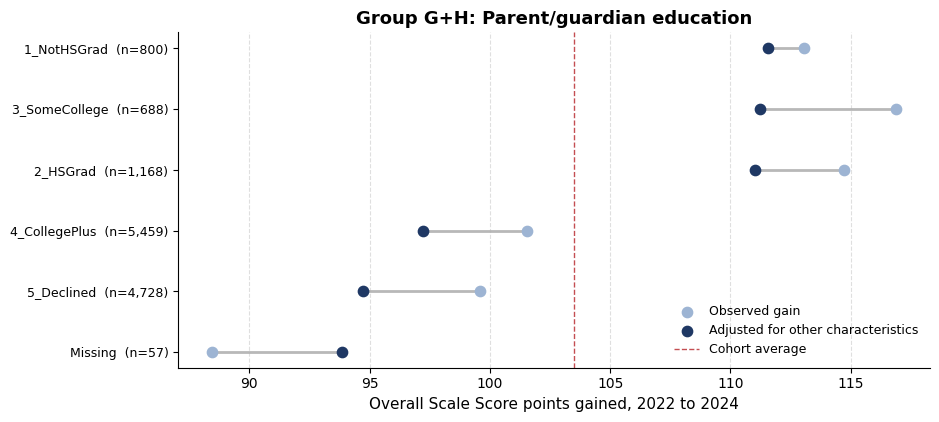

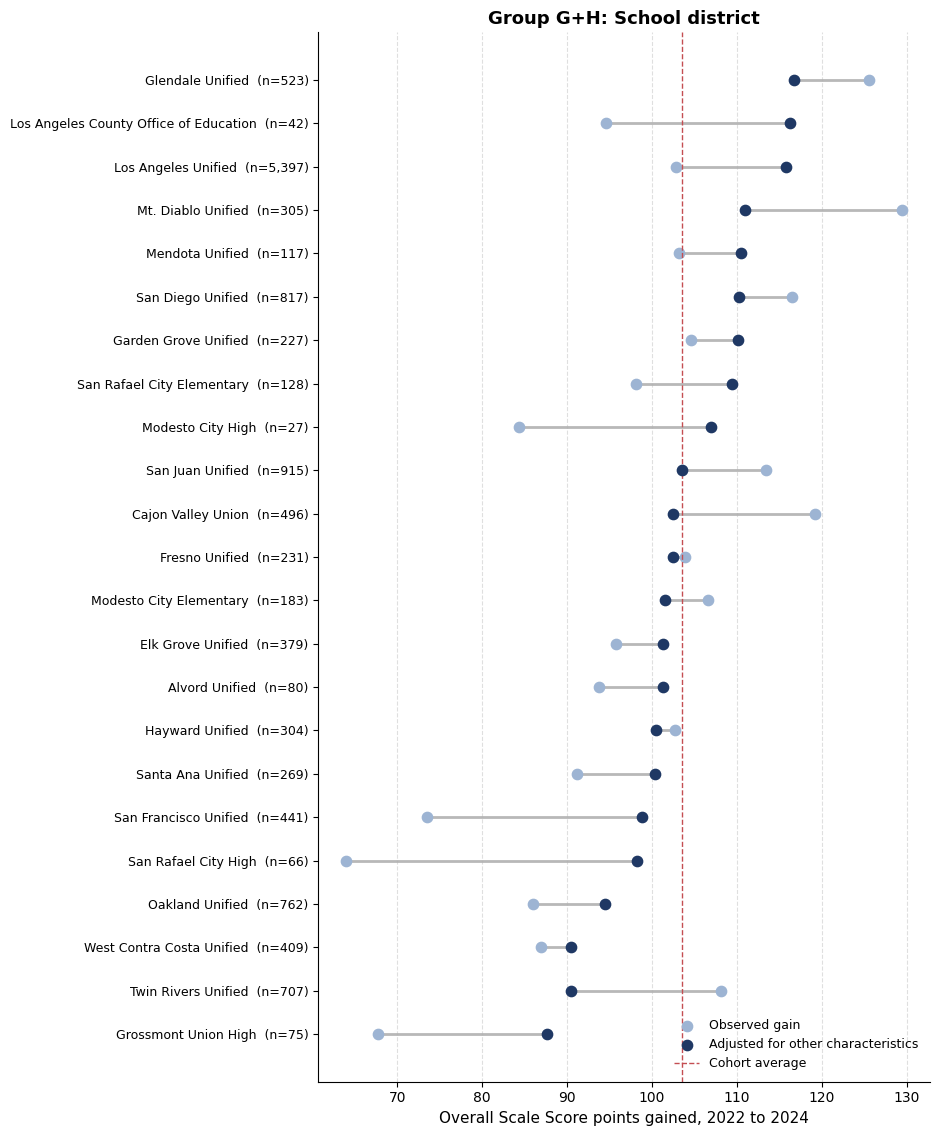

In [25]:
# %% [Cell C] One figure per characteristic: observed and adjusted on the same axis
import matplotlib.pyplot as plt

def dumbbell(t, title, fname):
    t = t.sort_values("Adjusted").reset_index(drop=True)
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(t) + 1.8))
    ax.hlines(y, t["Observed"], t["Adjusted"], color="#B8B8B8", lw=2, zorder=1)
    ax.scatter(t["Observed"], y, s=55, color="#9DB4D3", label="Observed gain", zorder=2)
    ax.scatter(t["Adjusted"], y, s=55, color="#1F3864",
               label="Adjusted for other characteristics", zorder=3)
    ax.axvline(model_df[OUTCOME].mean(), color="#C44E52", ls="--", lw=1, label="Cohort average")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{l}  (n={n:,})" for l, n in zip(t["Label"], t["Students"])], fontsize=9)
    ax.set_xlabel("Overall Scale Score points gained, 2022 to 2024", fontsize=11)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.grid(axis="x", ls="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=9, loc="lower right", frameon=False)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

TITLES = {"Grade": "Grade level in 2022", "BirthCountry": "Country of birth",
          "ParentEd": "Parent/guardian education", "Race": "Race and ethnicity",
          "Language": "Primary language", "Gender": "Gender",
          "SED": "Socioeconomically disadvantaged", "Migrant": "Migrant status",
          "Homeless": "Homeless program"}

for var in ["Grade", "BirthCountry", "ParentEd"]:
    dumbbell(oa[var], f"{group_label}: {TITLES[var]}", f"plots/{group_short}_obs_adj_{var}.png")
dumbbell(dist, f"{group_label}: School district", f"plots/{group_short}_obs_adj_District.png")



In [26]:
# %% [Cell D] Robustness: which rankings hold in grade-standardized SD units too?
# Fits the SD-unit version alongside, so the appendix can state plainly which
# findings do not depend on the choice of metric.

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sd_model = smf.mixedlm(build_formula("ZGain_fixed", "Z1_fixed", model_cats),
                           data=model_df, groups="District").fit(reml=True, method="lbfgs", maxiter=2000)

rows = []
for var in model_cats:
    a = observed_vs_adjusted(full_model, model_df, var, OUTCOME).set_index(var)["Adjusted"]
    b = observed_vs_adjusted(sd_model, model_df, var, "ZGain_fixed").set_index(var)["Adjusted"].reindex(a.index)
    ra, rb = a.rank(ascending=False, method="min"), b.rank(ascending=False, method="min")
    movers = [f"{pretty(var, l)} ({int(ra[l])} to {int(rb[l])})" for l in a.index if abs(ra[l] - rb[l]) >= 3]
    rows.append({"Characteristic": var, "Levels": len(a),
                 "Rank agreement, points vs SD (rho)": round(a.corr(b, method="spearman"), 2) if len(a) > 2 else None,
                 "Levels moving 3+ places": "; ".join(movers) or "none"})

sd_re = {d: float(np.asarray(v).ravel()[0]) for d, v in sd_model.random_effects.items()}
d_rho = dist.set_index("District")["District_effect"].corr(pd.Series(sd_re), method="spearman")
rows.append({"Characteristic": "District", "Levels": len(dist),
             "Rank agreement, points vs SD (rho)": round(d_rho, 2), "Levels moving 3+ places": "(see Cell B)"})

robust = pd.DataFrame(rows)
print(robust.to_string(index=False))
robust.to_csv(f"robustness_points_vs_sd_{group_short}.csv", index=False)

Characteristic  Levels  Rank agreement, points vs SD (rho)                                                                                           Levels moving 3+ places
         Grade      12                                0.29 Grade 2 (1 to 6); Grade 1 (2 to 8); Kindergarten (4 to 10); Grade 4 (5 to 1); Grade 9 (8 to 2); Grade 11 (9 to 3)
      ParentEd       6                                0.83                                                                                                              none
          Race       8                                0.95                                                                                                              none
  BirthCountry      15                                1.00                                                                                                              none
      Language       3                                1.00                                                                             